# Radiomics experiments and results

The historical experiments include repeated CT scans under different LNDb identifiers. The binary calibration/test experiments in section 11 exclude the confirmed copies.

All calculations below use saved predictions and models. No models are retrained. Each exported CSV retains the saved run directory in its `run` column.

## Tables used in the main notebook

Run this notebook from top to bottom to generate the tables displayed in [radiomics_analysis.ipynb](radiomics_analysis.ipynb). Reports are saved under `data/processed/`.

| Main section | Calculation and export | Output |
|---|---|---|
| 6.1 Spheres versus segmentation | [8.2 Matched region comparison](#82-spheres-versus-segmentation-on-shared-nodules) | `radiomics_region_comparison.csv` |
| 6.1 Five-class classification | [8.1 Five-class table](#81-five-class-table-for-the-main-notebook) | `radiomics_five_class_results.csv` |
| 6.2 Default binary decisions | [11.1 Default decisions](#111-default-decisions) | `radiomics_binary_default_results.csv` |
| 6.2 Duplicate-excluded binary ROC | [11.8 ROC and zero-FN points](#118-duplicate-excluded-roc-for-the-main-notebook) | `radiomics_binary_roc_points.csv` and `radiomics_binary_roc.png` |
| 6.2 Calibrated binary decisions | [11.6 Binary comparison](#116-binary-table-for-the-main-notebook) | `radiomics_binary_results.csv` |
| 6.3 Regression | [7.1 Regression table](#71-regression-table-for-the-main-notebook) | `radiomics_regression_results.csv` |
| 7.1 Remaining binary errors | [11.7 Paired errors](#117-baseline-versus-filtered-and-tuned-balanced-rf) | `radiomics_binary_errors.csv` |
| 7.2 Feature selection | [10.1 Feature-selection table](#101-feature-selection-table-for-the-main-notebook) | `radiomics_feature_selection_results.csv` |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "configs/paths.yaml").exists(), "Run from the repository root or notebooks/."
sys.path.insert(0, str(ROOT))

from src.modeling import feature_inventory, EXCLUDED_LNDB_IDS, metrics

KEYS = ["LNDbID", "FindingID"]
LIDC_KEYS = ["patient_id", "series_uid", "nodule_id"]
CLASSES = [1, 2, 3, 4, 5]
print("Repository:", ROOT)
print("Duplicate CTs excluded only with --exclude-duplicate-lndb:", sorted(EXCLUDED_LNDB_IDS))

Repository: /home/jp/Documents/por-definir-ds
Duplicate CTs excluded only with --exclude-duplicate-lndb: [181, 182, 183, 184, 185, 188, 189, 194, 195, 198, 226]


## 1. What features do we have?

Training data only. Each row counts nodules with extracted features in that CSV.

In [2]:
from src.modeling import feature_inventory

#for 2.5D, each slice has its own row.
display(feature_inventory(ROOT / "data"))

,dataset,region,method,CSV,nodules,rows,features
0,LIDC,circle,2.5D,lidc_circle_r11_5slice_hu.csv,2637,13185,930
1,LIDC,circle,2D,lidc_circle_r11_bw10_hu.csv,2637,2637,930
2,LIDC,circle,2D,lidc_circle_r11_clipped.csv,2637,2637,930
3,LIDC,circle,2D,lidc_circle_r11_hu.csv,2637,2637,930
4,LIDC,circle,2D,lidc_circle_r14_clipped.csv,2637,2637,930
5,LIDC,circle,2D,lidc_circle_r14_hu.csv,2637,2637,930
6,LIDC,circle,2D,lidc_circle_r17_clipped.csv,2637,2637,930
7,LIDC,circle,2D,lidc_circle_r17_hu.csv,2637,2637,930
8,LIDC,circle,2D,lidc_circle_r21_clipped.csv,2637,2637,930
9,LIDC,circle,2D,lidc_circle_r21_hu.csv,2637,2637,930


## 2. What did we change between experiments?

### Circle radii

We start with circles extracted from the original HU values and validate on all 765 LNDb training nodules. Consensus applies to segmentation masks, not circles.

We used the P95, P97 and P99 nodule-size percentiles to choose circle radii for LNDb and LIDC.

| Percentile | LNDb radius | LIDC radius |
|---|---:|---:|
| P95 | 6 mm | 14 mm |
| P97 | 7 mm | 17 mm |
| P99 | 11 mm | 21 mm |

Because nodule sizes differ between the datasets, we tried using each dataset’s radius. We also tried using the same radius in both datasets, taking the LNDb value, to see whether keeping the extraction region the same size works better. We additionally tried 11 mm in LIDC with 6 mm in LNDb.

In [3]:
def display_models(models):
    scores = {}
    for choice, name in models.items():
        table = pd.read_csv(ROOT / "models" / name / "metrics.csv")
        scores[choice] = table.loc[
            table["fold"].eq("overall_oof"),
            ["balanced_accuracy", "macro_f1", "qwk", "mae"],
        ].iloc[0]

    display(pd.DataFrame(scores).T.round(3))

In [4]:
models = {
    "same radius: LNDb 6, LIDC 6": "rf_lidc_circle_r6_hu_lndb_circle_r6_hu_balanced",
    "same radius: LNDb 7, LIDC 7": "rf_lidc_circle_r7_hu_lndb_circle_r7_hu_balanced",
    "same radius: LNDb 11, LIDC 11": "rf_lidc_circle_r11_hu_lndb_circle_r11_hu_balanced",
    "P95: LNDb 6, LIDC 14": "rf_circle_r14_r6_balanced_5class",
    "P97: LNDb 7, LIDC 17": "rf_circle_r17_r7_balanced_5class",
    "P99: LNDb 11, LIDC 21": "rf_lidc_circle_r21_hu_lndb_circle_r11_hu_balanced",
    "extra: LNDb 6, LIDC 11": "rf_lidc_circle_r11_hu_lndb_circle_r6_hu_balanced",
}

display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"same radius: LNDb 6, LIDC 6",0.382,0.383,0.443,0.725
"same radius: LNDb 7, LIDC 7",0.388,0.385,0.445,0.724
"same radius: LNDb 11, LIDC 11",0.360,0.369,0.351,0.790
"P95: LNDb 6, LIDC 14",0.409,0.422,0.435,0.698
"P97: LNDb 7, LIDC 17",0.375,0.388,0.435,0.690
"P99: LNDb 11, LIDC 21",0.345,0.371,0.352,0.736
"extra: LNDb 6, LIDC 11",0.408,0.429,0.442,0.685


We thought P99 might help by including more of the perinodular region, but both P99 choices had lower balanced accuracy than P95. Larger circles may also include nearby vessels and other tissue. These scores cannot tell us why the predictions changed. The P95 14/6 mm model and the extra 11/6 mm model are nearly tied on balanced accuracy (0.409 and 0.408). The 11/6 mm model has lower MAE (0.685 versus 0.698).

### Does clipping help?

As described in the preprocessing notebook, we also extracted features after clipping CT values to [-1000, 400] HU. We compare this with the original HU values using the same 14/6 mm circles, model and 765 LNDb nodules.

In [5]:
clipping_models = {
    "14/6 mm, original HU": "rf_circle_r14_r6_balanced_5class",
    "14/6 mm, clipped HU": "rf_circle_r14_r6_clipped_balanced_5class",
}

display_models(clipping_models)

,balanced_accuracy,macro_f1,qwk,mae
"14/6 mm, original HU",0.409,0.422,0.435,0.698
"14/6 mm, clipped HU",0.356,0.363,0.421,0.707


Clipping did not help this 14/6 mm model. Balanced accuracy fell from 0.409 to 0.356, and MAE rose from 0.698 to 0.707. The original HU values also gave higher macro F1 and QWK here.

### Do circles or 2D segmentations work better?

The radius comparisons above used all 765 LNDb nodules. Segmentation masks are available only for nodules ≥3 mm, so this comparison uses 622 LNDb nodules. We retrained the 14/6 mm circle model on exactly the same LNDb and LIDC nodules as the 2D, 50% consensus segmentation model.

In [6]:
models = {
    "circle, 14/6 mm": "rf_circle_r14_r6_ge3_c50_population_balanced",
    "2D segmentation, 50% consensus": "rf_segmentation_2d_c50_bw25_available_balanced",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"circle, 14/6 mm",0.397,0.427,0.414,0.711
"2D segmentation, 50% consensus",0.399,0.414,0.529,0.650


Balanced accuracy is nearly the same (0.397 for circles and 0.399 for segmentation). Segmentation has higher QWK (0.529 versus 0.414) and lower MAE (0.650 versus 0.711), while circles have higher macro F1 (0.427 versus 0.414). Circles use the slice nearest the centroid, whereas segmentation uses the slice with the largest mask area, so the region and selected slice both change.

### What changes with 2D mask consensus?

A higher consensus requires more readers to include a pixel in the mask. With 75% and 100% consensus, some masks become too small to extract features. The 25% and 50% models use 622 LNDb nodules. The 75% and 100% models use 614, so their overall scores also reflect a change in the training and validation population.

In [7]:
models = {
    "25%": "rf_segmentation_2d_c25_bw25_available_balanced",
    "50%": "rf_segmentation_2d_c50_bw25_available_balanced",
    "75%": "rf_segmentation_2d_c75_bw25_available_balanced",
    "100%": "rf_segmentation_2d_c100_bw25_available_balanced",
}
display_models(models)

lndb_ids = []
for level in (75, 100):
    lidc = pd.read_csv(ROOT / "data" / f"lidc_segmentation_2d_c{level}_hu.csv")
    lndb = pd.read_csv(ROOT / "models" / models[f"{level}%"] / "validation_predictions.csv")
    lndb_ids.append(set(zip(lndb.LNDbID, lndb.FindingID)))
    print(f"{level}%: {len(lidc)} LIDC, {len(lndb)} LNDb")

print("Same LNDb nodules:", lndb_ids[0] == lndb_ids[1])

,balanced_accuracy,macro_f1,qwk,mae
25%,0.388,0.399,0.493,0.666
50%,0.399,0.414,0.529,0.650
75%,0.379,0.394,0.503,0.674
100%,0.375,0.388,0.484,0.686


75%: 2630 LIDC, 614 LNDb


100%: 2628 LIDC, 614 LNDb
Same LNDb nodules: True


The 50% consensus model has the highest balanced accuracy, macro F1 and QWK, and the lowest MAE in this table. The 75% and 100% models also lose eight LNDb nodules and some LIDC nodules during extraction. Their score differences cannot be attributed to the consensus level alone.

### Does 3D segmentation help?

Both models use 50% consensus masks and validate on the same 622 LNDb nodules. The 2D model extracts features from one axial slice, while the 3D model uses the full mask volume. The 3D extraction also includes one more LIDC training nodule.

In [8]:
models = {
    "2D": "rf_segmentation_2d_c50_bw25_available_balanced",
    "3D": "rf_segmentation_3d_c50_bw25_ge3_balanced",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
2D,0.399,0.414,0.529,0.650
3D,0.428,0.446,0.523,0.632


The 3D model has higher balanced accuracy (0.428 versus 0.399) and macro F1 (0.446 versus 0.414), and lower MAE (0.632 versus 0.650). The 2D model has slightly higher QWK (0.529 versus 0.523). Since the LIDC training populations differ by one nodule, this does not isolate the effect of 2D versus 3D extraction completely.

### Does a 3D sphere help?

At 11/6 mm, compare a circle on one slice with a 3D sphere around the same centroid. Both models use all 765 LNDb training nodules.

In [9]:
models = {
    "2D circle, 11/6 mm": "rf_lidc_circle_r11_hu_lndb_circle_r6_hu_balanced",
    "3D sphere, 11/6 mm": "rf_sphere_bw25_balanced",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"2D circle, 11/6 mm",0.408,0.429,0.442,0.685
"3D sphere, 11/6 mm",0.399,0.416,0.489,0.655


The sphere has higher QWK (0.489 versus 0.442) and lower MAE (0.655 versus 0.685), but lower balanced accuracy (0.399 versus 0.408).

### Do spheres or 3D segmentations work better?

To compare a sphere with the 3D, 50% consensus segmentation, restrict the sphere model to the same 622 LNDb nodules. The full-population sphere score above is not directly comparable with this segmentation score.

In [10]:
models = {
    "3D sphere, LNDb ≥3 mm": "rf_sphere_bw25_ge3_balanced",
    "3D segmentation, 50%": "rf_segmentation_3d_c50_bw25_ge3_balanced",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"3D sphere, LNDb ≥3 mm",0.401,0.428,0.475,0.680
"3D segmentation, 50%",0.428,0.446,0.523,0.632


On these 622 nodules, 3D segmentation improves balanced accuracy (0.428 versus 0.401), QWK (0.523 versus 0.475) and MAE (0.632 versus 0.680) over the sphere. Unlike the sphere, it uses the provided nodule mask.

### Do five circle slices help?

We also trained a five-class RF using five adjacent circle slices instead of one. Each training nodule contributes five rows, although validation still counts each nodule once.

In [11]:
models = {
    "one circle slice, 11/6 mm": "rf_lidc_circle_r11_hu_lndb_circle_r6_hu_balanced",
    "five circle slices, 11/6 mm": "rf_circle_r11_r6_5slice_balanced",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"one circle slice, 11/6 mm",0.408,0.429,0.442,0.685
"five circle slices, 11/6 mm",0.353,0.373,0.396,0.708


For five-class prediction, five slices reduce balanced accuracy from 0.408 to 0.353 and QWK from 0.442 to 0.396. The binary result is a separate question below.

### Does a smaller bin width help?

As described in the radiomics decisions notebook, bin width groups CT values for texture features. Here we compare 25 HU with 10 HU using the same 11/6 mm circles and 765 LNDb nodules.

In [12]:
models = {
    "25 HU": "rf_lidc_circle_r11_hu_lndb_circle_r6_hu_balanced",
    "10 HU": "rf_circle_r11_r6_bw10_balanced",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
25 HU,0.408,0.429,0.442,0.685
10 HU,0.370,0.382,0.437,0.695


For these 11/6 mm circles, 25 HU gives higher balanced accuracy (0.408 versus 0.370), macro F1 and QWK, and lower MAE (0.685 versus 0.695) than 10 HU. This comparison does not establish the best bin width for other regions or radii.

## 3. Does training on LIDC or changing class balance help?

We keep the LNDb circle radius at 6 mm and compare training on LNDb alone with training on LNDb plus LIDC, using 14 mm circles for LIDC. Both models are evaluated on the same 765 LNDb nodules.

In [13]:
models = {
    "LNDb only, 6 mm": "rf_lndb_circle_r6_hu_balanced",
    "LNDb + LIDC, 14/6 mm": "rf_circle_r14_r6_balanced_5class",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"LNDb only, 6 mm",0.409,0.430,0.446,0.681
"LNDb + LIDC, 14/6 mm",0.409,0.422,0.435,0.698


No big difference.


The five-class labels are uneven. Among the 765 LNDb nodules, 254 are class 2 but only 18 are class 5. We first compare RF with and without class weights, then class weights, SMOTE and Balanced RF on the same 14/6 mm circles.

For 3D spheres and 50% consensus segmentations, compare the three balancing methods separately on the same 622 LNDb nodules ≥3 mm. The sphere results here use the ≥3 mm model, not the 765-nodule sphere model.

In [14]:
models = {
    "no class weights": "rf_circle_r14_r6_unweighted_5class",
    "balanced class weights": "rf_circle_r14_r6_balanced_5class",
}
display_models(models)
models = {
    "LNDb only, no class weights": "rf_lndb_circle_r6_hu",
    "LNDb only, balanced": "rf_lndb_circle_r6_hu_balanced",
}
display_models(models)
models = {
    "class weights": "rf_circle_r14_r6_balanced_5class",
    "SMOTE": "rf_circle_r14_r6_smote_5class",
    "balanced RF": "brf_circle_r14_r6_5class",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
no class weights,0.385,0.402,0.467,0.667
balanced class weights,0.409,0.422,0.435,0.698


,balanced_accuracy,macro_f1,qwk,mae
"LNDb only, no class weights",0.379,0.393,0.458,0.672
"LNDb only, balanced",0.409,0.430,0.446,0.681


,balanced_accuracy,macro_f1,qwk,mae
class weights,0.409,0.422,0.435,0.698
SMOTE,0.412,0.399,0.439,0.736
balanced RF,0.426,0.323,0.414,0.809


In [15]:
models = {
    "class weights, 3D sphere": "rf_sphere_bw25_ge3_balanced",
    "SMOTE, 3D sphere": "rf_sphere_ge3_smote_5class",
    "Balanced RF, 3D sphere": "brf_sphere_ge3_5class",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"class weights, 3D sphere",0.401,0.428,0.475,0.680
"SMOTE, 3D sphere",0.452,0.436,0.500,0.722
"Balanced RF, 3D sphere",0.484,0.385,0.477,0.788


In [16]:
models = {
    "class weights, 3D segmentation": "rf_segmentation_3d_c50_bw25_ge3_balanced",
    "SMOTE, 3D segmentation": "rf_segmentation_3d_c50_ge3_smote_5class",
    "Balanced RF, 3D segmentation": "brf_segmentation_3d_c50_ge3_5class",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"class weights, 3D segmentation",0.428,0.446,0.523,0.632
"SMOTE, 3D segmentation",0.445,0.435,0.504,0.698
"Balanced RF, 3D segmentation",0.480,0.416,0.519,0.743


With 14/6 mm circles, Balanced RF has the highest balanced accuracy among these three balancing methods, but class-weighted RF has higher macro F1 and lower MAE. On both 3D regions, Balanced RF again has the highest balanced accuracy (0.484 for spheres and 0.480 for segmentations), while class-weighted RF has lower MAE (0.680 and 0.632). No balancing method wins on every metric.

## 4. Do fewer features help?

First compare all 14/6 mm circle features with top 100, top 500, Original-only and normalized pairs for each balancing method. Original-only uses features from the CT image without additional filters. Normalized pairs keeps other features, but removes a measure's non-normalized version when its `Normalized` version exists.

Then compare all features with top 100, 500 and 1000 for class-weighted RF on 11/6 mm 3D spheres and 50% consensus 3D segmentations. Balanced RF feature selection is also shown where trained. The 3D models use the same 622 LNDb nodules ≥3 mm, while circles use 765 nodules. Top-k uses [ANOVA F scores](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.f_classif.html) and is selected inside each training fold.

In [17]:
models = {
    "all, class weights": "rf_circle_r14_r6_balanced_5class",
    "top 100, class weights": "rf_circle_r14_r6_balanced_k100_5class",
    "top 500, class weights": "rf_circle_r14_r6_balanced_k500_5class",
    "Original only, class weights": "rf_circle_r14_r6_balanced_original_5class",
    "normalized pairs, class weights": "rf_circle_r14_r6_balanced_normalized_pairs_5class",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"all, class weights",0.409,0.422,0.435,0.698
"top 100, class weights",0.355,0.370,0.428,0.697
"top 500, class weights",0.396,0.416,0.432,0.699
"Original only, class weights",0.362,0.382,0.434,0.718
"normalized pairs, class weights",0.395,0.425,0.429,0.693


In [18]:
models = {
    "all, SMOTE": "rf_circle_r14_r6_smote_5class",
    "top 100, SMOTE": "rf_circle_r14_r6_smote_k100_5class",
    "top 500, SMOTE": "rf_circle_r14_r6_smote_k500_5class",
    "Original only, SMOTE": "rf_circle_r14_r6_smote_original_5class",
    "normalized pairs, SMOTE": "rf_circle_r14_r6_smote_normalized_pairs_5class",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"all, SMOTE",0.412,0.399,0.439,0.736
"top 100, SMOTE",0.340,0.323,0.424,0.766
"top 500, SMOTE",0.409,0.389,0.433,0.749
"Original only, SMOTE",0.359,0.329,0.403,0.841
"normalized pairs, SMOTE",0.405,0.396,0.430,0.750


In [19]:
models = {
    "all, Balanced RF": "brf_circle_r14_r6_5class",
    "top 100, Balanced RF": "brf_circle_r14_r6_k100_5class",
    "top 500, Balanced RF": "brf_circle_r14_r6_k500_5class",
    "Original only, Balanced RF": "brf_circle_r14_r6_original_5class",
    "normalized pairs, Balanced RF": "brf_circle_r14_r6_normalized_pairs_5class",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"all, Balanced RF",0.426,0.323,0.414,0.809
"top 100, Balanced RF",0.420,0.334,0.435,0.783
"top 500, Balanced RF",0.417,0.313,0.402,0.825
"Original only, Balanced RF",0.424,0.315,0.390,0.843
"normalized pairs, Balanced RF",0.434,0.332,0.419,0.799


In [20]:
models = {
    "all, 3D sphere": "rf_sphere_bw25_ge3_balanced",
    "top 100, 3D sphere": "rf_sphere_ge3_balanced_k100_5class",
    "top 500, 3D sphere": "rf_sphere_ge3_balanced_k500_5class",
    "top 1000, 3D sphere": "rf_sphere_ge3_balanced_k1000_5class",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"all, 3D sphere",0.401,0.428,0.475,0.680
"top 100, 3D sphere",0.414,0.443,0.485,0.670
"top 500, 3D sphere",0.410,0.432,0.492,0.677
"top 1000, 3D sphere",0.380,0.401,0.456,0.704


In [21]:
models = {
    "all, 3D sphere Balanced RF": "brf_sphere_ge3_5class",
    "top 100, 3D sphere Balanced RF": "brf_sphere_ge3_k100_5class",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"all, 3D sphere Balanced RF",0.484,0.385,0.477,0.788
"top 100, 3D sphere Balanced RF",0.466,0.387,0.482,0.778


In [22]:
models = {
    "all, 3D segmentation RF": "rf_segmentation_3d_c50_bw25_ge3_balanced",
    "top 100, 3D segmentation RF": "rf_segmentation_3d_c50_ge3_balanced_k100_5class",
    "top 500, 3D segmentation RF": "rf_segmentation_3d_c50_ge3_balanced_k500_5class",
    "top 1000, 3D segmentation RF": "rf_segmentation_3d_c50_ge3_balanced_k1000_5class",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"all, 3D segmentation RF",0.428,0.446,0.523,0.632
"top 100, 3D segmentation RF",0.425,0.447,0.504,0.638
"top 500, 3D segmentation RF",0.412,0.430,0.495,0.662
"top 1000, 3D segmentation RF",0.409,0.426,0.504,0.656


In [23]:
models = {
    "all, 3D segmentation Balanced RF": "brf_segmentation_3d_c50_ge3_5class",
    "top 100, 3D segmentation Balanced RF": "brf_segmentation_3d_c50_ge3_k100_5class",
    "top 500, 3D segmentation Balanced RF": "brf_segmentation_3d_c50_ge3_k500_5class",
    "top 1000, 3D segmentation Balanced RF": "brf_segmentation_3d_c50_ge3_k1000_5class",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"all, 3D segmentation Balanced RF",0.480,0.416,0.519,0.743
"top 100, 3D segmentation Balanced RF",0.456,0.415,0.520,0.719
"top 500, 3D segmentation Balanced RF",0.446,0.400,0.505,0.759
"top 1000, 3D segmentation Balanced RF",0.468,0.411,0.515,0.752


With circles, top-k selection does not improve balanced accuracy for class-weighted RF or SMOTE. Balanced RF improves from 0.426 to 0.434 with normalized pairs, but still has higher MAE than class-weighted RF.

For 3D spheres, class-weighted RF improves across all four metrics with top 100 (balanced accuracy 0.414 versus 0.401 with all features). For 3D segmentation, all features have the highest balanced accuracy within both RF settings (0.428 with class weights and 0.480 with Balanced RF). Feature reduction helps the sphere RF, but not the 3D segmentation models on balanced accuracy.

## 5. How do Balanced RF and XGBoost compare?

Compare both models using all features within each region: 14/6 mm circles on 765 LNDb nodules, then 11/6 mm 3D spheres and 50% consensus 3D segmentations on the same 622 LNDb nodules ≥3 mm. Balanced RF undersamples each tree, while XGBoost uses balanced sample weights, so this tests the complete model settings rather than the algorithm alone.

In [24]:
models = {
    "Balanced RF, 14/6 mm circles": "brf_circle_r14_r6_5class",
    "XGBoost, 14/6 mm circles": "xgboost_circle_r14_r6_balanced_5class",
}
display_models(models)

models = {
    "Balanced RF, 3D sphere": "brf_sphere_ge3_5class",
    "XGBoost, 3D sphere": "xgboost_sphere_ge3_balanced_5class",
}
display_models(models)

models = {
    "Balanced RF, 3D segmentation": "brf_segmentation_3d_c50_ge3_5class",
    "XGBoost, 3D segmentation": "xgboost_segmentation_3d_c50_ge3_balanced_5class",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
"Balanced RF, 14/6 mm circles",0.426,0.323,0.414,0.809
"XGBoost, 14/6 mm circles",0.436,0.386,0.489,0.718


,balanced_accuracy,macro_f1,qwk,mae
"Balanced RF, 3D sphere",0.484,0.385,0.477,0.788
"XGBoost, 3D sphere",0.442,0.410,0.502,0.725


,balanced_accuracy,macro_f1,qwk,mae
"Balanced RF, 3D segmentation",0.480,0.416,0.519,0.743
"XGBoost, 3D segmentation",0.455,0.430,0.529,0.712


With circles, XGBoost outperforms Balanced RF on all four metrics. With 3D spheres and segmentations, Balanced RF has higher balanced accuracy (0.484 and 0.480 versus 0.442 and 0.455), while XGBoost has higher macro F1 and QWK and lower MAE. These are matched comparisons within each region, not across the 765- and 622-nodule populations.

### Earlier RF tuning at 11/6 mm

The saved comparison below tunes ordinary RF on 11/6 mm circles and also shows a separate normalized-pairs feature test. It does not tune the 14/6 mm or 3D Balanced RF and XGBoost models.

In [25]:
models = {
    "ordinary RF": "rf_lidc_circle_r11_hu_lndb_circle_r6_hu_balanced",
    "tuned RF": "rf_lidc_circle_r11_hu_lndb_circle_r6_hu_balanced_tuned",
    "normalized pairs": "rf_lidc_circle_r11_hu_lndb_circle_r6_hu_balanced_normalized_pairs",
}
display_models(models)

,balanced_accuracy,macro_f1,qwk,mae
ordinary RF,0.408,0.429,0.442,0.685
tuned RF,0.406,0.414,0.447,0.686
normalized pairs,0.404,0.433,0.433,0.685


Tuning gives almost the same balanced accuracy as ordinary RF (0.406 versus 0.408), with a small QWK increase (0.447 versus 0.442). Normalized pairs give slightly higher macro F1 (0.433 versus 0.429) but lower balanced accuracy and QWK. MAE is 0.685 for both ordinary RF and normalized pairs.

## 6. Which high-rated nodules do the models miss?

Evaluate every model below on the **same 471 LNDb nodules** with saved validation predictions. Of these, 70 have reader-mean rating 4, 18 have rating 5, and 380 have a mean below 3. Three more have a mean above 3 but round to rating 3; they count in neither the rating-4/5 recall nor the low-rating specificity. These are radiologist ratings, not confirmed cancer.

An alert means a predicted rating of 4–5. **Recall (sensitivity)** measures alerts among the 88 rating-4/5 nodules. **Specificity** measures how often the 380 lower-rated nodules avoid an alert. The five-class models also trained on mean-3 nodules excluded from binary training.

### Five-class models

These five-class models validate on at least 622 nodules, but the table uses only the 471 shared nodules. The 2D and 3D segmentations use 50% consensus masks. Only ordinary RF has a saved 2D segmentation model. Its circle model was trained on the same population as the 2D segmentation model; Balanced RF and XGBoost circle models trained on a larger population. The region differences do not isolate the effect of extraction alone.

In [26]:
five_class_models = {
    ("RF, class weights", "circle (14/6 mm)"): "rf_circle_r14_r6_ge3_c50_population_balanced",
    ("RF, class weights", "2D segmentation (50%)"): "rf_segmentation_2d_c50_bw25_available_balanced",
    ("RF, class weights", "3D sphere (11/6 mm)"): "rf_sphere_bw25_ge3_balanced",
    ("RF, class weights", "3D segmentation (50%)"): "rf_segmentation_3d_c50_bw25_ge3_balanced",
    ("Balanced RF", "circle (14/6 mm)"): "brf_circle_r14_r6_5class",
    ("Balanced RF", "3D sphere (11/6 mm)"): "brf_sphere_ge3_5class",
    ("Balanced RF", "3D segmentation (50%)"): "brf_segmentation_3d_c50_ge3_5class",
    ("XGBoost, class weights", "circle (14/6 mm)"): "xgboost_circle_r14_r6_balanced_5class",
    ("XGBoost, class weights", "3D sphere (11/6 mm)"): "xgboost_sphere_ge3_balanced_5class",
    ("XGBoost, class weights", "3D segmentation (50%)"): "xgboost_segmentation_3d_c50_ge3_balanced_5class",
}

In [27]:
keys = KEYS + ["fold"]
five_class_validation = pd.read_csv(
    ROOT / "models" / five_class_models[("RF, class weights", "3D segmentation (50%)")]
    / "validation_predictions.csv"
)[keys + ["target_classification_mean"]]
binary_labels = pd.read_csv(
    ROOT / "data/processed/lndb_ge3_nodule_targets.csv"
).rename(columns={"NoduleID": "FindingID"})
binary_validation = five_class_validation.merge(
    binary_labels[KEYS + ["target_binary_mean"]], on=KEYS, validate="one_to_one"
).dropna(subset=["target_binary_mean"])
assert len(five_class_validation) == 622 and len(binary_validation) == 471

def alert_table(models):
    rows = []
    for (model, region), name in models.items():
        predictions = pd.read_csv(ROOT / "models" / name / "validation_predictions.csv")
        shared = binary_validation.merge(
            predictions, on=keys, how="left", suffixes=("", "_saved"), validate="one_to_one"
        )
        assert len(shared) == 471 and shared.prediction.notna().all()
        assert shared.target_classification_mean.eq(shared.target_classification_mean_saved).all()
        class_4 = shared.target_classification_mean.eq(4)
        class_5 = shared.target_classification_mean.eq(5)
        low = shared.target_binary_mean.eq(0)
        alert = shared.prediction.ge(4)
        missed_4 = int((class_4 & ~alert).sum())
        missed_5 = int((class_5 & ~alert).sum())
        false_alerts = int((low & alert).sum())
        assert (class_4.sum(), class_5.sum(), low.sum()) == (70, 18, 380)
        rows.append({
            "model": model, "region": region,
            "missed rating 4 / 70": missed_4,
            "missed rating 5 / 18": missed_5,
            "missed ratings 4–5 / 88": missed_4 + missed_5,
            "rating 4–5 recall": 1 - (missed_4 + missed_5) / 88,
            "specificity": 1 - false_alerts / 380,
            "false alerts / 380": false_alerts,
        })
    return pd.DataFrame(rows).set_index(["model", "region"]).round(3)

display(alert_table(five_class_models))

missed rating 4 / 70  \
model                  region                                        
RF, class weights      circle (14/6 mm)                         58   
                       2D segmentation (50%)                    45   
                       3D sphere (11/6 mm)                      53   
                       3D segmentation (50%)                    47   
Balanced RF            circle (14/6 mm)                         48   
                       3D sphere (11/6 mm)                      32   
                       3D segmentation (50%)                    23   
XGBoost, class weights circle (14/6 mm)                         42   
                       3D sphere (11/6 mm)                      34   
                       3D segmentation (50%)                    31   

                                              missed rating 5 / 18  \
model                  region                                        
RF, class weights      circle (14/6 mm)                          7   
                       2D segmentation (50%)                     5   
                       3D sphere (11/6 mm)                       6   
                       3D segmentation (50%)                     6   
Balanced RF            circle (14/6 mm)                          3   
                       3D sphere (11/6 mm)                       3   
                       3D segmentation (50%)                     2   
XGBoost, class weights circle (14/6 mm)                          3   
                       3D sphere (11/6 mm)                       4   
                       3D segmentation (50%)                     3   

                                              missed ratings 4–5 / 88  \
model                  region                                           
RF, class weights      circle (14/6 mm)                            65   
                       2D segmentation (50%)                       50   
                       3D sphere (11/6 mm)                         59   
                       3D segmentation (50%)                       53   
Balanced RF            circle (14/6 mm)                            51   
                       3D sphere (11/6 mm)                         35   
                       3D segmentation (50%)                       25   
XGBoost, class weights circle (14/6 mm)                            45   
                       3D sphere (11/6 mm)                         38   
                       3D segmentation (50%)                       34   

                                              rating 4–5 recall  specificity  \
model                  region                                                  
RF, class weights      circle (14/6 mm)                   0.261        0.979   
                       2D segmentation (50%)              0.432        0.955   
                       3D sphere (11/6 mm)                0.330        0.963   
                       3D segmentation (50%)              0.398        0.955   
Balanced RF            circle (14/6 mm)                   0.420        0.900   
                       3D sphere (11/6 mm)                0.602        0.892   
                       3D segmentation (50%)              0.716        0.866   
XGBoost, class weights circle (14/6 mm)                   0.489        0.924   
                       3D sphere (11/6 mm)                0.568        0.911   
                       3D segmentation (50%)              0.614        0.879   

                                              false alerts / 380  
model                  region                                     
RF, class weights      circle (14/6 mm)                        8  
                       2D segmentation (50%)                  17  
                       3D sphere (11/6 mm)                    14  
                       3D segmentation (50%)                  17  
Balanced RF            circle (14/6 mm)                       38  
                       3D sphere (11/6 mm)               

Five-class 3D segmentation Balanced RF misses the fewest high-rated nodules (25/88, including 2/18 rated 5). It alerts on 63/88 versus 53/88 with a 3D sphere and 37/88 with circles, but raises 51 versus 41 and 38 false alerts among the 380 lower-rated nodules. For RF, 2D segmentation alerts on 38/88 versus 23/88 with its population-matched circle model, with 17 versus 8 false alerts.

## 7. Does regression provide useful alerts?

Ridge predicts the **unrounded radiologist mean**. Compare the three regions on the same 622 LNDb nodules using continuous MAE/RMSE, rounded five-class QWK, and signed error on true ratings 4–5. A negative signed error means systematic underprediction. Continuous error uses raw predictions, even when they fall outside 1–5. The earlier 11/6 mm circle run covers 765 nodules and is kept separate.

For alerts, restrict all three models to the **same 471 nodules as section 6**. The saved five-class prediction rounds the continuous value to 1–5 (an alert starts at **3.5**). A derived binary prediction alerts when the continuous value is **above 3**. Both thresholds are fixed, not chosen using validation outcomes. Of the 471, 88 have rating 4–5, 91 have an unrounded mean above 3, and 380 have a mean below 3. Three binary-1 nodules round to rating 3. These are reader ratings, not confirmed diagnoses.

In [28]:
from src.regression import regression_metrics

ridge_models = {
    "circle (14/6 mm)": "ridge_circle_r14_r6_ge3",
    "3D sphere (11/6 mm)": "ridge_sphere_ge3",
    "3D segmentation (50%)": "ridge_segmentation_3d_c50_ge3",
}
targets = pd.read_csv(ROOT / "data/processed/lndb_ge3_nodule_targets.csv")
binary_targets = targets.rename(columns={"NoduleID": "FindingID"})[
    KEYS + ["target_binary_mean"]
]
regression_rows, alert_rows = [], []
for region, name in ridge_models.items():
    predictions = pd.read_csv(ROOT / "models" / name / "validation_predictions.csv")
    assert len(predictions) == 622 and not predictions.duplicated(KEYS).any()
    pd.testing.assert_frame_equal(
        five_class_validation.set_index(KEYS).sort_index(),
        predictions.set_index(KEYS).sort_index()[["fold", "target_classification_mean"]],
        check_dtype=False,
    )
    assert predictions.prediction.eq(
        np.clip(np.floor(predictions.prediction_continuous + 0.5), 1, 5)
    ).all()
    high = predictions.target_classification_mean.ge(4)
    scores = regression_metrics(predictions.target_regression_mean, predictions.prediction_continuous)
    regression_rows.append({
        "region": region,
        "continuous MAE": scores["mae"],
        "continuous RMSE": scores["rmse"],
        "bias on ratings 4–5": (predictions.loc[high, "prediction_continuous"]
                                - predictions.loc[high, "target_regression_mean"]).mean(),
        "predictions outside 1–5": int((~predictions.prediction_continuous.between(1, 5)).sum()),
        "rounded five-class QWK": metrics(predictions.target_classification_mean,
                                          predictions.prediction)["qwk"],
    })
    shared = predictions.merge(binary_targets, on=KEYS, validate="one_to_one")
    shared = shared.loc[shared.target_binary_mean.notna()].copy()
    rating_4 = shared.target_classification_mean.eq(4)
    rating_5 = shared.target_classification_mean.eq(5)
    binary_1 = shared.target_binary_mean.eq(1)
    binary_0 = shared.target_binary_mean.eq(0)
    assert len(shared) == 471 and (rating_4.sum(), rating_5.sum()) == (70, 18)
    assert (binary_1.sum(), binary_0.sum()) == (91, 380)
    assert binary_1.eq(shared.target_regression_mean.gt(3)).all()
    for rule, alert in {
        "rounded 1–5 (alert 4–5)": shared.prediction.ge(4),
        "binary (mean >3)": shared.prediction_continuous.gt(3),
    }.items():
        missed_4 = int((rating_4 & ~alert).sum())
        missed_5 = int((rating_5 & ~alert).sum())
        false_alerts = int((binary_0 & alert).sum())
        alert_rows.append({
            "region": region, "alert rule": rule,
            "missed rating 4 / 70": missed_4,
            "missed rating 5 / 18": missed_5,
            "missed ratings 4–5 / 88": missed_4 + missed_5,
            "rating 4–5 recall": 1 - (missed_4 + missed_5) / 88,
            "binary-1 recall": int((binary_1 & alert).sum()) / 91,
            "specificity": 1 - false_alerts / 380,
            "false alerts / 380": false_alerts,
        })
display(pd.DataFrame(regression_rows).set_index("region").round(3))
display(pd.DataFrame(alert_rows).set_index(["region", "alert rule"]).round(3))

,continuous MAE,continuous RMSE,bias on ratings 4–5,predictions outside 1–5,rounded five-class QWK
region,,,,,
circle (14/6 mm),0.805,1.053,-1.150,35,0.378
3D sphere (11/6 mm),0.916,2.175,-1.488,59,0.418
3D segmentation (50%),0.821,1.140,-1.094,52,0.427


missed rating 4 / 70  \
region                alert rule                                      
circle (14/6 mm)      rounded 1–5 (alert 4–5)                    53   
                      binary (mean >3)                           44   
3D sphere (11/6 mm)   rounded 1–5 (alert 4–5)                    54   
                      binary (mean >3)                           37   
3D segmentation (50%) rounded 1–5 (alert 4–5)                    51   
                      binary (mean >3)                           33   

                                               missed rating 5 / 18  \
region                alert rule                                      
circle (14/6 mm)      rounded 1–5 (alert 4–5)                    11   
                      binary (mean >3)                            5   
3D sphere (11/6 mm)   rounded 1–5 (alert 4–5)                     9   
                      binary (mean >3)                            6   
3D segmentation (50%) rounded 1–5 (alert 4–5)                     9   
                      binary (mean >3)                            5   

                                               missed ratings 4–5 / 88  \
region                alert rule                                         
circle (14/6 mm)      rounded 1–5 (alert 4–5)                       64   
                      binary (mean >3)                              49   
3D sphere (11/6 mm)   rounded 1–5 (alert 4–5)                       63   
                      binary (mean >3)                              43   
3D segmentation (50%) rounded 1–5 (alert 4–5)                       60   
                      binary (mean >3)                              38   

                                               rating 4–5 recall  \
region                alert rule                                   
circle (14/6 mm)      rounded 1–5 (alert 4–5)              0.273   
                      binary (mean >3)                     0.443   
3D sphere (11/6 mm)   rounded 1–5 (alert 4–5)              0.284   
                      binary (mean >3)                     0.511   
3D segmentation (50%) rounded 1–5 (alert 4–5)              0.318   
                      binary (mean >3)                     0.568   

                                               binary-1 recall  specificity  \
region                alert rule                                              
circle (14/6 mm)      rounded 1–5 (alert 4–5)            0.286        0.968   
                      binary (mean >3)                   0.451        0.866   
3D sphere (11/6 mm)   rounded 1–5 (alert 4–5)            0.286        0.932   
                      binary (mean >3)                   0.505        0.850   
3D segmentation (50%) rounded 1–5 (alert 4–5)            0.308        0.979   
                      binary (mean >3)                   0.571        0.845   

                                               false alerts / 380  
region                alert rule                                   
circle (14/6 mm)      rounded 1–5 (alert 4–5)                  12  
                      binary (mean >3)                         51  
3D sphere (11/6 mm)   rounded 1–5 (alert 4–5)                  26  
                      binary (mean >3)                         57  
3D segmentation (50%) rounded 1–5 (alert 4–5)                   8  
                      binary (mean >3)                         59

The main concern is missed nodules rated 4–5. On the same nodules, five-class Ridge misses 60/88, compared with 25/88 for five-class Balanced RF. Binary Ridge misses 38/88, compared with 33/88 for binary XGBoost. Ridge therefore does not reduce the most important error. Its five-class conversion has fewer false positives (8 versus 51), but its binary conversion has more (59 versus 49). These are radiologist ratings, not confirmed cancer diagnoses.

### 7.1 Regression table for the main notebook

Inputs are the three Ridge runs listed in `ridge_models`, using `models/<run>/validation_predictions.csv`. Continuous errors are measured against the unrounded reader mean. QWK uses rounded five-class predictions. All three runs have the same 622 findings, targets and folds.

This exports `data/processed/radiomics_regression_results.csv` for main section 6.3. The detailed alert-conversion table above remains on its separate 471-nodule population.

In [29]:
regression_report = pd.DataFrame(regression_rows)
regression_report["run"] = regression_report.region.map(ridge_models)
regression_report["nodules"] = 622
regression_report["region"] = regression_report.region.map({
    "circle (14/6 mm)": "Circle",
    "3D sphere (11/6 mm)": "Sphere",
    "3D segmentation (50%)": "Segmentation",
})
regression_report = regression_report[[
    "region", "run", "nodules", "continuous MAE", "continuous RMSE",
    "rounded five-class QWK",
]]
report_path = ROOT / "data/processed/radiomics_regression_results.csv"
regression_report.to_csv(report_path, index=False)
display(regression_report.set_index("region").drop(columns=["run", "nodules"]).round(3))
print("Saved:", report_path.relative_to(ROOT))

,continuous MAE,continuous RMSE,rounded five-class QWK
region,,,
Circle,0.805,1.053,0.378
Sphere,0.916,2.175,0.418
Segmentation,0.821,1.140,0.427


Saved: data/processed/radiomics_regression_results.csv


## 8. Which models are best?

The first table compares the listed five-class models and rounded Ridge on the same 622 LNDb nodules. The all-nodule ranking below uses 765 findings and is reported separately.

Combined score = [balanced accuracy + macro F1 + QWK + (1 − MAE)] / 4. Higher is better.

In [30]:
candidates = {
    **five_class_models,
    **{("Ridge", region): name for region, name in ridge_models.items()},
    ("RF, volume correlation ≤0.7", "3D segmentation (50%)"):
        "rf_segmentation_3d_c50_ge3_maxsize0.7",
    ("RF, normalized pairs", "3D segmentation (50%)"):
        "rf_segmentation_3d_c50_ge3_normalized_pairs",
    ("RF + SMOTE", "3D sphere (11/6 mm)"): "rf_sphere_ge3_smote_5class",
    ("RF, top 100", "3D sphere (11/6 mm)"): "rf_sphere_ge3_balanced_k100_5class",
}
rows = []
for (model, region), name in candidates.items():
    predictions = pd.read_csv(ROOT / "models" / name / "validation_predictions.csv")
    shared = five_class_validation.merge(
        predictions[KEYS + ["fold", "prediction"]],
        on=KEYS + ["fold"], validate="one_to_one",
    )
    assert len(shared) == 622
    rows.append({"model": f"{model} — {region}",
                 **metrics(shared.target_classification_mean, shared.prediction)})
def add_combined_score(table):
    table = table.copy()
    table["combined score"] = (
        table["balanced_accuracy"] + table["macro_f1"]
        + table["qwk"] + (1 - table["mae"])
    ) / 4
    return table

scores = pd.DataFrame(rows).set_index("model")
leaders = list(dict.fromkeys(
    scores.nlargest(2, "qwk").index.tolist()
    + scores.nlargest(2, "balanced_accuracy").index.tolist()
    + scores.nlargest(2, "macro_f1").index.tolist()
    + scores.nsmallest(2, "mae").index.tolist()
))
display(scores.loc[leaders].sort_values("qwk", ascending=False).rename(columns={
    "balanced_accuracy": "balanced accuracy", "macro_f1": "macro F1",
    "qwk": "QWK", "mae": "MAE",
}).round(3))

,balanced accuracy,macro F1,QWK,MAE
model,,,,
"RF, normalized pairs — 3D segmentation (50%)",0.427,0.444,0.531,0.627
"RF, class weights — 2D segmentation (50%)",0.399,0.414,0.529,0.650
"RF, volume correlation ≤0.7 — 3D segmentation (50%)",0.447,0.466,0.527,0.627
"RF, class weights — 3D segmentation (50%)",0.428,0.446,0.523,0.632
Balanced RF — 3D segmentation (50%),0.480,0.416,0.519,0.743
Balanced RF — 3D sphere (11/6 mm),0.484,0.385,0.477,0.788


### 8.1 Five-class table for the main notebook

Inputs are saved `models/<run>/validation_predictions.csv` files. Only five-class runs matching all 765 findings, targets and folds in `data/processed/lndb_nodule_targets.csv` and `lndb_patient_folds.csv` enter this ranking. Metrics are recalculated from the predictions.

This exports the full ranking to `data/processed/radiomics_five_class_results.csv`. Main section 6.1 displays its first five rows. The `run` column identifies the source folder for every row. Display names are labels only and do not affect ranking.

In [31]:
keys = KEYS + ["fold"]
reference_targets = pd.read_csv(
    ROOT / "data/processed/lndb_nodule_targets.csv"
).rename(columns={"NoduleID": "FindingID"})
reference_folds = pd.read_csv(ROOT / "data/processed/lndb_patient_folds.csv")
reference = reference_targets.merge(
    reference_folds, on="LNDbID", validate="many_to_one"
).set_index(keys).sort_index()["target_classification_mean"]
assert len(reference) == 765 and reference.index.is_unique

rows = []
for file in sorted((ROOT / "models").glob("*/validation_predictions.csv")):
    if "grid4" in file.parent.name and not (file.parent / "tuning.csv").exists():
        continue  # Earlier directories named grid4 were not actually tuned.
    predictions = pd.read_csv(file)
    if len(predictions) != 765 or "target_classification_mean" not in predictions:
        continue
    assert not predictions.duplicated(KEYS).any(), file.parent.name
    predictions = predictions.set_index(keys).sort_index()
    if not predictions.target_classification_mean.equals(reference):
        continue
    assert predictions.prediction.isin(CLASSES).all(), file.parent.name
    rows.append({
        "model": file.parent.name,
        **metrics(reference, predictions.prediction),
    })

all_nodules = add_combined_score(pd.DataFrame(rows).set_index("model"))
model_labels = {
    "rf_sphere_smote_5class": "RF + SMOTE, sphere",
    "rf_sphere_smote_aux": "RF + SMOTE + auxiliary targets, sphere",
    "rf_sphere_balanced_k100_5class": "Class-weighted RF, sphere, top 100",
    "expert_sphere_gldm": "RF + SMOTE, sphere, GLDM features",
    "expert_sphere_firstorder": "RF + SMOTE, sphere, intensity features",
}
five_class_report = all_nodules.sort_values(
    "combined score", ascending=False
).rename_axis("run").reset_index()
five_class_report.insert(
    0, "model", five_class_report.run.map(model_labels).fillna(five_class_report.run)
)
five_class_report["nodules"] = 765
five_class_report = five_class_report.rename(columns={
    "balanced_accuracy": "balanced accuracy", "macro_f1": "macro F1",
    "qwk": "QWK", "mae": "MAE",
})
report_path = ROOT / "data/processed/radiomics_five_class_results.csv"
five_class_report.to_csv(report_path, index=False)
display(five_class_report.set_index("model").drop(columns=["run", "nodules"]).head(5).round(3))
print("Saved:", report_path.relative_to(ROOT))

,balanced accuracy,macro F1,QWK,MAE,combined score
model,,,,,
"RF + SMOTE, sphere",0.458,0.429,0.539,0.672,0.439
"RF + SMOTE + auxiliary targets, sphere",0.449,0.424,0.528,0.678,0.430
"Class-weighted RF, sphere, top 100",0.407,0.428,0.513,0.654,0.423
"RF + SMOTE, sphere, GLDM features",0.438,0.412,0.504,0.697,0.414
"RF + SMOTE, sphere, intensity features",0.436,0.406,0.514,0.702,0.414


Saved: data/processed/radiomics_five_class_results.csv


### 8.2 Spheres versus segmentation on shared nodules

This table compares four training settings using 3D spheres and 50% consensus 3D segmentations. All eight runs use the same 622 LNDb findings, reader targets and patient folds. The historical runs include the duplicate CT copies.

The run mapping below identifies each input `models/<run>/validation_predictions.csv`. Metrics are recalculated and checked against that run's `metrics.csv`.

Output: `data/processed/radiomics_region_comparison.csv`, displayed first in main section 6.1. Its `run` column retains the source directory.

In [32]:
region_runs = {
    ("Class-weighted RF", "Sphere"): "rf_sphere_bw25_ge3_balanced",
    ("Class-weighted RF", "Segmentation"): "rf_segmentation_3d_c50_bw25_ge3_balanced",
    ("RF + SMOTE", "Sphere"): "rf_sphere_ge3_smote_5class",
    ("RF + SMOTE", "Segmentation"): "rf_segmentation_3d_c50_ge3_smote_5class",
    ("Balanced RF", "Sphere"): "brf_sphere_ge3_5class",
    ("Balanced RF", "Segmentation"): "brf_segmentation_3d_c50_ge3_5class",
    ("Class-weighted XGBoost", "Sphere"): "xgboost_sphere_ge3_balanced_5class",
    ("Class-weighted XGBoost", "Segmentation"): "xgboost_segmentation_3d_c50_ge3_balanced_5class",
}
region_reference = five_class_validation.set_index(KEYS).sort_index()
region_rows = []
for (model, region), run in region_runs.items():
    predictions = pd.read_csv(
        ROOT / "models" / run / "validation_predictions.csv"
    ).set_index(KEYS).sort_index()
    assert predictions.index.is_unique and len(predictions) == 622
    pd.testing.assert_frame_equal(
        region_reference, predictions[["fold", "target_classification_mean"]],
        check_dtype=False,
    )
    result = metrics(predictions.target_classification_mean, predictions.prediction)
    stored = pd.read_csv(ROOT / "models" / run / "metrics.csv")
    overall = stored.loc[stored.fold.eq("overall_oof"), list(result)]
    assert len(overall) == 1
    np.testing.assert_allclose(overall.iloc[0], list(result.values()), atol=1e-12, rtol=0)
    region_rows.append({
        "model": model, "region": region, "run": run,
        "nodules": len(predictions), **result,
    })

region_report = add_combined_score(pd.DataFrame(region_rows)).rename(columns={
    "balanced_accuracy": "balanced accuracy", "macro_f1": "macro F1",
    "qwk": "QWK", "mae": "MAE",
})
report_path = ROOT / "data/processed/radiomics_region_comparison.csv"
region_report.to_csv(report_path, index=False)
display(region_report.set_index(["model", "region"]).drop(columns=["run", "nodules"]).round(3))
print("Saved:", report_path.relative_to(ROOT))

balanced accuracy  macro F1    QWK  \
model                  region                                             
Class-weighted RF      Sphere                    0.401     0.428  0.475   
                       Segmentation              0.428     0.446  0.523   
RF + SMOTE             Sphere                    0.452     0.436  0.500   
                       Segmentation              0.445     0.435  0.504   
Balanced RF            Sphere                    0.484     0.385  0.477   
                       Segmentation              0.480     0.416  0.519   
Class-weighted XGBoost Sphere                    0.442     0.410  0.502   
                       Segmentation              0.455     0.430  0.529   

                                       MAE  combined score  
model                  region                               
Class-weighted RF      Sphere        0.680           0.406  
                       Segmentation  0.632           0.441  
RF + SMOTE             Sphere        0.722           0.416  
                       Segmentation  0.698           0.422  
Balanced RF            Sphere        0.788           0.389  
                       Segmentation  0.743           0.418  
Class-weighted XGBoost Sphere        0.725           0.407  
                       Segmentation  0.712           0.425

Saved: data/processed/radiomics_region_comparison.csv


## 9. Why does the leading model miss high-rated nodules?

The five-class 3D segmentation Balanced RF misses 25 of the 88 nodules rated 4–5 in the 622-nodule ≥3 mm set, fewer than the other compared models. Three checks describe the errors: how the model compares with radiologist-to-radiologist agreement, where the misses sit relative to the 3/4 boundary, and how the misses relate to nodule size.

A rating of 4–5 is a radiologist rating, or the rounded mean of several ratings, not a confirmed cancer diagnosis.

### Reader-to-reader and model-to-mean agreement

The 219 LNDb nodules with two or more readers allow a baseline: how well one radiologist matches the mean of the other radiologists. The table compares that baseline with the model on the same nodules, and also shows the model on all 622 nodules. “Same rating” and “within one rating” are fractions from 0 to 1. Higher is better except the mean rating gap.

In [33]:
import ast

from sklearn.metrics import cohen_kappa_score

def agreement(target, prediction):
    target = np.asarray(target, dtype=float)
    prediction = np.asarray(prediction, dtype=float)
    gap = np.abs(target - prediction)
    return {
        "QWK": cohen_kappa_score(target, prediction, weights="quadratic"),
        "same rating": (gap == 0).mean(),
        "within one rating": (gap <= 1).mean(),
        "mean rating gap": gap.mean(),
    }

five_class = pd.read_csv(ROOT / "models/brf_segmentation_3d_c50_ge3_5class/validation_predictions.csv")
reader_ratings = pd.read_csv(ROOT / "data/processed/lndb_ge3_nodule_targets.csv").rename(
    columns={"NoduleID": "FindingID"}
)
audit = five_class.merge(
    reader_ratings[KEYS + ["ratings", "target_regression_mean"]],
    on=KEYS, validate="one_to_one",
)
audit["votes"] = audit.ratings.map(ast.literal_eval)
assert len(audit) == 622

multi = audit[audit.votes.map(len).gt(1)]
assert len(multi) == 219
first_reader = multi.votes.map(lambda votes: votes[0])
other_readers = multi.votes.map(lambda votes: int(np.floor(np.mean(votes[1:]) + 0.5)))
comparisons = {
    "One radiologist vs the mean of the other radiologists (219 nodules)": agreement(first_reader, other_readers),
    "Five-class Balanced RF vs the readership mean (same 219 nodules)": agreement(
        multi.target_classification_mean, multi.prediction
    ),
    "Five-class Balanced RF vs the readership mean (all 622 nodules)": agreement(
        audit.target_classification_mean, audit.prediction
    ),
}
display(pd.DataFrame(comparisons).T.round(3))

,QWK,same rating,within one rating,mean rating gap
One radiologist vs the mean of the other radiologists (219 nodules),0.554,0.457,0.872,0.699
Five-class Balanced RF vs the readership mean (same 219 nodules),0.576,0.452,0.831,0.735
Five-class Balanced RF vs the readership mean (all 622 nodules),0.519,0.445,0.844,0.743


On the same 219 nodules, model-to-mean QWK is 0.576 and the first-reader-to-other-readers QWK is 0.554. The mean rating gaps are 0.74 and 0.70. These comparisons use different reference ratings, so they do not establish equivalent clinical performance or quantify how much disagreement explains model error.

### The misses sit at the 3/4 boundary

The 88 nodules rated 4–5, grouped by their unrounded readership mean. “3.5” is exactly halfway between 3 and 4 and still rounds up to 4. The predicted columns show where the model sends each group. “One reader” marks nodules with a single radiologist, where no second opinion exists for comparison.

In [34]:
high = audit[audit.target_classification_mean.ge(4)].copy()
assert len(high) == 88
high["band"] = np.select(
    [high.target_regression_mean.lt(4), high.target_regression_mean.eq(4)],
    ["3.5 (rounds up to 4)", "4.0"], default="above 4.0",
)
bands = ["3.5 (rounds up to 4)", "4.0", "above 4.0"]
missed_mid = high[high.band.eq("4.0") & high.prediction.lt(4)]
assert missed_mid.votes.map(len).eq(1).all()
rows = []
for band in bands:
    group = high[high.band.eq(band)]
    rows.append({
        "nodules": len(group),
        "one reader": int(group.votes.map(len).eq(1).sum()),
        **{f"predicted {value}": int(group.prediction.eq(value).sum()) for value in CLASSES},
    })
display(pd.DataFrame(rows, index=bands))

,nodules,one reader,predicted 1,predicted 2,predicted 3,predicted 4,predicted 5
3.5 (rounds up to 4),15,0,1,4,1,8,1
4.0,54,45,1,11,5,24,13
above 4.0,19,8,1,1,0,7,10


Of the 25 missed nodules, 23 have a readership mean of 3.5 or 4.0. Only 2 of the 19 nodules rated above 4.0 were missed, and 10 of those 19 were predicted exactly 5. Every missed nodule with mean 4.0 has a single reader, so that rating cannot be checked against a second radiologist.

### The misses concentrate in the smallest nodules

All 622 nodules split into four size groups by the length of the segmentation mask. The table counts the nodules rated 4–5 in each group and how many of them the model missed.

In [35]:
mask_length = pd.read_csv(
    ROOT / "data/lndb_ge3_segmentation_3d_c50_hu.csv",
    usecols=KEYS + ["original_shape_MajorAxisLength"],
)
sized = audit.merge(mask_length, on=KEYS, validate="one_to_one")
assert len(sized) == 622
sized["size group"] = pd.qcut(
    sized.original_shape_MajorAxisLength, 4,
    labels=["Q1 smallest", "Q2", "Q3", "Q4 largest"],
)
rows = []
for group_name in ["Q1 smallest", "Q2", "Q3", "Q4 largest"]:
    group = sized[sized["size group"].eq(group_name)]
    rated_high = group[group.target_classification_mean.ge(4)]
    rows.append({
        "nodules": len(group),
        "median mask axis (mm)": group.original_shape_MajorAxisLength.median(),
        "rated 4–5": len(rated_high),
        "rated 4–5 missed": int(rated_high.prediction.lt(4).sum()),
    })
display(pd.DataFrame(rows, index=["Q1 smallest", "Q2", "Q3", "Q4 largest"]).round(1))

,nodules,median mask axis (mm),rated 4–5,rated 4–5 missed
Q1 smallest,156,4.6,3,3
Q2,155,5.8,10,9
Q3,155,7.3,17,5
Q4 largest,156,11.6,58,8


The model finds 1 of the 13 nodules rated 4–5 in the two smallest size groups and 50 of 58 in the largest. Misses are associated with nodule size and reader-mean rating in this cohort. The smaller groups contain few high-rated nodules.

### Reader disagreement within each class: historical circle RF

This preserves the older circle-model diagnostic on 765 nodules. The source run is `rf_lidc_circle_r11_hu_lndb_circle_r6_hu_balanced`. The table separates single-reader nodules from multi-reader nodules with equal or different ratings, and reports class recall within each group.

In [36]:
circle_run = "rf_lidc_circle_r11_hu_lndb_circle_r6_hu_balanced"
circle_targets = pd.read_csv(
    ROOT / "data/processed/lndb_nodule_targets.csv"
).rename(columns={"NoduleID": "FindingID"})
circle_predictions = pd.read_csv(
    ROOT / "models" / circle_run / "validation_predictions.csv"
)
circle_reader_data = circle_targets.merge(
    circle_predictions[KEYS + ["prediction"]], on=KEYS, validate="one_to_one"
)
assert len(circle_reader_data) == 765
circle_votes = circle_reader_data.ratings.map(ast.literal_eval)
np.testing.assert_array_equal(
    np.floor(circle_votes.map(np.mean) + 0.5).astype(int),
    circle_reader_data.target_classification_mean,
)
circle_reader_data["reader group"] = [
    "single reader" if len(votes) == 1 else
    "multiple, agree" if min(votes) == max(votes) else "multiple, disagree"
    for votes in circle_votes
]
circle_reader_data["correct"] = circle_reader_data.prediction.eq(
    circle_reader_data.target_classification_mean
)
display(circle_reader_data.groupby(
    ["target_classification_mean", "reader group"]
).agg(n=("correct", "size"), recall=("correct", "mean")).round(3))

n  recall
target_classification_mean reader group                   
1                          multiple, agree      32   0.969
                           multiple, disagree    5   0.400
                           single reader       176   0.472
2                          multiple, agree      23   0.478
                           multiple, disagree   44   0.568
                           single reader       187   0.572
3                          multiple, agree      20   0.350
                           multiple, disagree   62   0.355
                           single reader       127   0.370
4                          multiple, agree       7   0.429
                           multiple, disagree   18   0.056
                           single reader        46   0.109
5                          multiple, agree       5   0.200
                           multiple, disagree    5   0.600
                           single reader         8   0.500

## 10. How much of the model is associated with nodule size?

Some radiomics features correlate strongly with nodule volume. The comparisons below test a size-only baseline and removal of highly volume-correlated features using the same 622 LNDb nodules and patient folds.

The reference here is ordinary class-weighted RF, not the Balanced RF used in section 9. Feature filtering is fitted on training rows only.

In [37]:
import joblib

leading = "rf_segmentation_3d_c50_bw25_ge3_balanced"
saved = joblib.load(ROOT / "models" / leading / "model.joblib")
forest = saved["model"].steps[-1][1]
features = saved["features"]

nodules = pd.read_csv(ROOT / "data/lndb_ge3_segmentation_3d_c50_hu.csv")
size_correlation = nodules[features].corrwith(nodules.original_shape_MeshVolume, method="spearman").abs()
importance = pd.Series(forest.feature_importances_, index=features)

groups = {
    "Top 50 features by importance": importance.nlargest(50).index,
    "Top 100 features by importance": importance.nlargest(100).index,
    "All 2060 features": features,
}
display(pd.DataFrame([
    {
        "features": name,
        "median |correlation with size|": size_correlation[names].median(),
        "share above 0.6": (size_correlation[names] > 0.6).mean(),
    }
    for name, names in groups.items()
]).set_index("features").round(3))

,median |correlation with size|,share above 0.6
features,,
Top 50 features by importance,0.946,0.700
Top 100 features by importance,0.924,0.670
All 2060 features,0.475,0.375


Among the top 50 features by forest importance, 70% have absolute Spearman correlation with mask volume above 0.6. Their median absolute correlation is 0.95, compared with 0.48 across all 2060 features. These are descriptive correlations on LNDb, separate from the training-fold feature-selection procedure.

In [38]:
size_models = {
    "All features (leading model)": "rf_segmentation_3d_c50_bw25_ge3_balanced",
    "Size only (one feature)": "rf_size_only_ge3",
    "Drop features above 0.9": "rf_segmentation_3d_c50_ge3_maxsize0.9",
    "Drop features above 0.7": "rf_segmentation_3d_c50_ge3_maxsize0.7",
    "Normalized texture where available": "rf_segmentation_3d_c50_ge3_normalized_pairs",
}
display_models(size_models)

,balanced_accuracy,macro_f1,qwk,mae
All features (leading model),0.428,0.446,0.523,0.632
Size only (one feature),0.274,0.275,0.240,0.952
Drop features above 0.9,0.422,0.440,0.513,0.638
Drop features above 0.7,0.447,0.466,0.527,0.627
Normalized texture where available,0.427,0.444,0.531,0.627


The size-only baseline has balanced accuracy 0.274 and QWK 0.240, below the full model's 0.428 and 0.523. Filtering at 0.7 improves the four overall metrics. Normalized feature pairs give slightly higher QWK than that filter.

The following table also checks whether the improved overall scores reduce missed high-rated nodules.

### 10.1 Feature-selection table for the main notebook

Inputs are `validation_predictions.csv` and `metrics.csv` in the two run folders listed below. Both runs use class-weighted RF, the same 622 findings and the same saved folds. Only the feature filter changes.

This exports `data/processed/radiomics_feature_selection_results.csv` for main section 7.2, including missed ratings 4–5 alongside the overall metrics.

In [39]:
selection_runs = {
    "All features": "rf_segmentation_3d_c50_bw25_ge3_balanced",
    "Volume correlation ≤0.7": "rf_segmentation_3d_c50_ge3_maxsize0.7",
}
selection_rows = []
selection_reference = None
for label, run in selection_runs.items():
    predictions = pd.read_csv(
        ROOT / "models" / run / "validation_predictions.csv"
    ).set_index(KEYS).sort_index()
    assert predictions.index.is_unique and len(predictions) == 622
    cohort = predictions[["fold", "target_classification_mean"]]
    if selection_reference is None:
        selection_reference = cohort
    pd.testing.assert_frame_equal(selection_reference, cohort, check_dtype=False)
    result = metrics(predictions.target_classification_mean, predictions.prediction)
    stored = pd.read_csv(ROOT / "models" / run / "metrics.csv")
    overall = stored.loc[stored.fold.eq("overall_oof"), list(result)]
    assert len(overall) == 1
    np.testing.assert_allclose(overall.iloc[0], list(result.values()), atol=1e-12, rtol=0)
    high = predictions.target_classification_mean.ge(4)
    selection_rows.append({
        "model": label, "run": run, "nodules": len(predictions), **result,
        "rated 4–5": int(high.sum()),
        "missed ratings 4–5": int((high & predictions.prediction.lt(4)).sum()),
    })

feature_report = add_combined_score(pd.DataFrame(selection_rows)).rename(columns={
    "balanced_accuracy": "balanced accuracy", "macro_f1": "macro F1",
    "qwk": "QWK", "mae": "MAE",
})
report_path = ROOT / "data/processed/radiomics_feature_selection_results.csv"
feature_report.to_csv(report_path, index=False)
display(feature_report.set_index("model").drop(columns=["run", "nodules"]).round(3))
print("Saved:", report_path.relative_to(ROOT))

,balanced accuracy,macro F1,QWK,MAE,rated 4–5,missed ratings 4–5,combined score
model,,,,,,,
All features,0.428,0.446,0.523,0.632,88,53,0.441
Volume correlation ≤0.7,0.447,0.466,0.527,0.627,88,55,0.453


Saved: data/processed/radiomics_feature_selection_results.csv


In [40]:
from scipy.stats import spearmanr

volume = pd.read_csv(
    ROOT / "data/lndb_ge3_segmentation_3d_c50_hu.csv",
    usecols=KEYS + ["original_shape_MeshVolume"],
)
volume["size (mm)"] = 2 * (3 * volume.original_shape_MeshVolume / (4 * np.pi)) ** (1 / 3)
readers = pd.read_csv(ROOT / "data/processed/lndb_ge3_nodule_targets.csv").rename(
    columns={"NoduleID": "FindingID"}
)
predictions = pd.read_csv(ROOT / "models" / leading / "validation_predictions.csv")
sized = (
    predictions.merge(volume, on=KEYS, validate="one_to_one")
    .merge(readers[KEYS + ["target_regression_mean"]], on=KEYS, validate="one_to_one")
)
assert len(sized) == 622

rows = []
for rating in CLASSES:
    said = sized[sized.prediction.eq(rating)]
    rated = sized[sized.target_classification_mean.eq(rating)]
    rows.append({
        "nodules the model calls so": len(said),
        "median size when it calls it (mm)": said["size (mm)"].median(),
        "nodules the readers rate so": len(rated),
        "median size when they rate it (mm)": rated["size (mm)"].median(),
    })
display(pd.DataFrame(rows, index=[f"rating {name}" for name in CLASSES]).round(1))

,nodules the model calls so,median size when it calls it (mm),nodules the readers rate so,median size when they rate it (mm)
rating 1,90,4.4,138,4.5
rating 2,144,3.9,197,4.5
rating 3,325,5.3,199,5.2
rating 4,50,11.0,70,6.9
rating 5,13,22.5,18,12.2


Nodules predicted as rating 4 have a median mask-equivalent diameter of 11.0 mm, versus 6.9 mm among nodules readers rated 4. For rating 5 the corresponding medians are 22.5 and 12.2 mm. These describe associations between size and predictions, not decision thresholds.

In [41]:
readers = sized.target_regression_mean
decile = pd.qcut(sized["size (mm)"], 10, labels=False)

circles = pd.read_csv(ROOT / "models/rf_lndb_circle_r6_hu_balanced/validation_predictions.csv")
combined = pd.read_csv(
    ROOT / "models/rf_circle_r14_r6_ge3_c50_population_balanced/validation_predictions.csv"
)
filtered = pd.read_csv(ROOT / "models/rf_segmentation_3d_c50_ge3_maxsize0.7/validation_predictions.csv")
rows = [{"model": "Readers (mean of ratings)", "QWK": None,
         "prediction against size": spearmanr(readers, sized["size (mm)"]).statistic,
         "rise from smallest to largest size decile": readers.groupby(decile).mean().iloc[-1] - readers.groupby(decile).mean().iloc[0]}]
for label, table in [
    ("Circle, LNDb only (6 mm)", circles),
    ("Circle, LNDb + LIDC (14/6 mm)", combined),
    ("3D segmentation, LNDb + LIDC", predictions),
    ("3D segmentation, 462 size features dropped", filtered),
]:
    shared = sized[KEYS + ["target_classification_mean", "size (mm)"]].merge(
        table[KEYS + ["prediction"]], on=KEYS, validate="one_to_one"
    )
    rows.append({
        "model": label,
        "QWK": cohen_kappa_score(shared.target_classification_mean, shared.prediction, weights="quadratic", labels=CLASSES),
        "prediction against size": spearmanr(shared.prediction, shared["size (mm)"]).statistic,
        "rise from smallest to largest size decile": shared.prediction.groupby(pd.qcut(shared["size (mm)"], 10, labels=False)).mean().pipe(lambda curve: curve.iloc[-1] - curve.iloc[0]),
    })
display(pd.DataFrame(rows).set_index("model").round(3))

,QWK,prediction against size,rise from smallest to largest size decile
model,,,
Readers (mean of ratings),NaN,0.376,1.675
"Circle, LNDb only (6 mm)",0.401,0.356,1.444
"Circle, LNDb + LIDC (14/6 mm)",0.414,0.247,1.095
"3D segmentation, LNDb + LIDC",0.523,0.560,2.048
"3D segmentation, 462 size features dropped",0.527,0.531,1.810


The circle predictions have weaker size associations than the segmentation predictions in this comparison. The mean reader rating rises by 1.7 points from the smallest to largest size decile, compared with 2.0 for the segmentation RF and 1.8 after filtering. Region choice, training populations and other feature differences limit causal interpretation.

In [42]:
sphere_saved = joblib.load(ROOT / "models/rf_sphere_bw25_ge3_balanced/model.joblib")
sphere_features = sphere_saved["features"]
sphere_importance = pd.Series(sphere_saved["model"].steps[-1][1].feature_importances_, index=sphere_features)
sphere_table = pd.read_csv(ROOT / "data/lndb_sphere_r6_hu.csv").merge(volume, on=KEYS, validate="one_to_one")
sphere_correlation = sphere_table[sphere_features].corrwith(
    sphere_table.original_shape_MeshVolume, method="spearman").abs()

groups = {
    "Top 50 sphere features": sphere_importance.nlargest(50).index,
    "All 2046 sphere features": sphere_features,
}
display(pd.DataFrame([
    {
        "features": name,
        "median |correlation with size|": sphere_correlation[names].median(),
        "share above 0.7": (sphere_correlation[names] > 0.7).mean(),
    }
    for name, names in groups.items()
]).set_index("features").round(3))
print(f"Segmentation features above 0.7: {int((size_correlation > 0.7).sum())} of {len(features)}")

sphere_predictions = pd.read_csv(ROOT / "models/rf_sphere_bw25_ge3_balanced/validation_predictions.csv")
sphere_sized = volume.merge(sphere_predictions[KEYS + ["prediction", "target_classification_mean"]], on=KEYS)
assert len(sphere_sized) == 622

rows = []
for rating in CLASSES:
    said = sphere_sized[sphere_sized.prediction.eq(rating)]
    rated = sphere_sized[sphere_sized.target_classification_mean.eq(rating)]
    rows.append({
        "nodules the sphere model calls so": len(said),
        "median size when it calls it (mm)": said["size (mm)"].median(),
        "nodules the readers rate so": len(rated),
        "median size when they rate it (mm)": rated["size (mm)"].median(),
    })
display(pd.DataFrame(rows, index=[f"rating {name}" for name in CLASSES]).round(1))

/home/jp/Documents/por-definir-ds/.venv/lib/python3.9/site-packages/pandas/core/nanops.py:1624: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


,median |correlation with size|,share above 0.7
features,,
Top 50 sphere features,0.403,0.0
All 2046 sphere features,0.274,0.0


Segmentation features above 0.7: 573 of 2060


,nodules the sphere model calls so,median size when it calls it (mm),nodules the readers rate so,median size when they rate it (mm)
rating 1,85,4.8,138,4.5
rating 2,212,4.5,197,4.5
rating 3,276,5.3,199,5.2
rating 4,36,9.9,70,6.9
rating 5,13,16.5,18,12.2


No sphere feature exceeds absolute correlation 0.7 with mask volume on these 622 LNDb nodules. A fixed extraction radius does not rule out intensity or texture associations with nodule size. Feature-selection decisions still need training-fold measurements.

The sphere model also predicts high ratings for larger nodules on average than the readers do. These comparisons do not establish that reader disagreement causes the remaining errors.

## 11. Binary segmentation

The objective is to miss as few positive nodules as possible while still rejecting negative nodules. Only 3D segmentation models are considered.

The saved binary label is **1 for reader mean >3**, **0 for mean <3**. Means of exactly 3 are excluded. These are radiologist ratings, not confirmed cancer diagnoses. The comparison uses the same **471 LNDb nodules: 91 positive and 380 negative**. Three positives have a mean above 3 but round to rating 3. LIDC is added to training only.

**Sensitivity** is the share of positives detected. **Specificity** is the share of negatives correctly rejected. **Accuracy** counts both. Calling everything negative gives 80.7% accuracy but misses all 91 positives. Calling everything positive has zero FN but only 19.3% accuracy and 0% specificity here. With zero FN, 30% accuracy needs at least 51 of the 380 negatives correctly rejected. This is much less demanding than 30% specificity.

The first comparisons retain the historical population, including confirmed CT copies. The separate threshold-validation experiment excludes those copies and is reported separately.

In [43]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, roc_auc_score, roc_curve

from src.binary_evaluation import binary_metrics, zero_fn_summary

KEYS = ["LNDbID", "FindingID"]
LABEL = "target_binary_mean"
readers = pd.read_csv(ROOT / "data/processed/lndb_ge3_nodule_targets.csv").rename(
    columns={"NoduleID": "FindingID"}
).set_index(KEYS)
binary_models = {
    "XGBoost, all features": "xgboost_segmentation_3d_c50_ge3_balanced_binary_roc",
    "Balanced RF, all features": "brf_segmentation_3d_c50_ge3_binary_roc",
    "RF, all features": "rf_segmentation_3d_c50_ge3_balanced_binary",
    "RF, intensity only": "rf_segmentation_firstorder_balanced_binary",
}
derived_models = {
    "Five-class RF, all features": "expert_segmentation_ge3",
    "Five-class RF, intensity only": "expert_segmentation_firstorder",
}

def load(name):
    table = pd.read_csv(ROOT / "models" / name / "validation_predictions.csv").set_index(KEYS)
    assert table.index.is_unique
    return table

tables = {label: load(name) for label, name in {**binary_models, **derived_models}.items()}
shared = readers.index[readers[LABEL].notna()]
for table in tables.values():
    shared = shared.intersection(table.index)
shared = shared.sort_values()
tables = {label: table.loc[shared] for label, table in tables.items()}
y = readers.loc[shared, LABEL].astype(int)
assert len(y) == 471 and y.sum() == 91
reference_folds = next(iter(tables.values())).fold
for label, table in tables.items():
    assert table.fold.equals(reference_folds), label
    if LABEL in table:
        assert table[LABEL].astype(int).equals(y), label

# Refreshed models add saved probabilities without changing the historical alerts.
for old, new in [
    ("xgboost_segmentation_3d_c50_ge3_balanced_binary", "XGBoost, all features"),
    ("brf_segmentation_3d_c50_ge3_binary", "Balanced RF, all features"),
]:
    assert load(old).loc[shared, "prediction"].equals(tables[new].prediction)

def score(table):
    return table.proba_1 if "proba_0" in table else table.proba_4 + table.proba_5

def summary(predictions):
    return binary_metrics(y, predictions)

columns = ["FN", "FP", "sensitivity", "specificity", "accuracy", "precision"]
print(f"Shared nodules: {len(y)}, positive: {y.sum()}, negative: {y.eq(0).sum()}")

def binary_report_scores(target, prediction, scores=None):
    result = binary_metrics(target, prediction)
    result["macro F1"] = f1_score(
        target, prediction, labels=[0, 1], average="macro", zero_division=0
    )
    result["AUC"] = roc_auc_score(target, scores) if scores is not None else np.nan
    return result

binary_report_columns = [
    "FN", "FP", "accuracy", "balanced_accuracy", "macro F1",
    "sensitivity", "specificity", "precision", "AUC",
]


Shared nodules: 471, positive: 91, negative: 380


### 11.1 Default decisions

Inputs are the `validation_predictions.csv` files listed in `binary_models`. The table recalculates FN, FP, accuracy, balanced accuracy, macro F1, recall, specificity, precision and AUC on the same 471 findings and saved folds.

`data/processed/radiomics_binary_default_results.csv` supplies the first table in main section 6.2. It selects the three binary-trained recipes with saved probability scores. The full table also retains RF with all features, whose saved predictions have no probability column.

In [44]:
default = pd.DataFrame({
    label: binary_report_scores(
        y, tables[label].prediction,
        tables[label].proba_1 if "proba_0" in tables[label] else None,
    ) for label in binary_models
}).T
default[["FN", "FP"]] = default[["FN", "FP"]].astype(int)
display(default[binary_report_columns].rename(columns={
    "balanced_accuracy": "balanced accuracy", "sensitivity": "recall",
}).round(3))

default_labels = {
    "XGBoost, all features": "XGBoost",
    "Balanced RF, all features": "Balanced RF",
    "RF, intensity only": "RF, intensity only",
}
default_report = default.loc[list(default_labels), binary_report_columns].copy()
default_report["run"] = [binary_models[label] for label in default_report.index]
default_report["nodules"] = len(y)
default_report["positives"] = int(y.sum())
default_report = default_report.rename(index=default_labels, columns={
    "balanced_accuracy": "balanced accuracy", "sensitivity": "recall",
}).rename_axis("model").reset_index()
report_path = ROOT / "data/processed/radiomics_binary_default_results.csv"
default_report.to_csv(report_path, index=False)
print("Saved:", report_path.relative_to(ROOT))

,FN,FP,accuracy,balanced accuracy,macro F1,recall,specificity,precision,AUC
"XGBoost, all features",33,49,0.826,0.754,0.738,0.637,0.871,0.542,0.881
"Balanced RF, all features",34,53,0.815,0.743,0.725,0.626,0.861,0.518,0.865
"RF, all features",49,30,0.832,0.691,0.707,0.462,0.921,0.583,NaN
"RF, intensity only",47,27,0.843,0.706,0.724,0.484,0.929,0.620,0.872


Saved: data/processed/radiomics_binary_default_results.csv


### 11.2 Retrospective zero-FN thresholds and ROC curves

The binary-trained models use P(1). The separately labelled five-class references use P(4)+P(5), evaluated against the same binary target. They are not binary-trained models.

For each model, the threshold is the **lowest positive score on these evaluated rows**, and a score equal to the threshold triggers an alert. This gives the highest specificity with zero FN on this curve. It is a **retrospective operating point**, not an independently validated threshold. AUC describes the whole ranking, not specifically its high-sensitivity end.

,training,threshold,FN,FP,accuracy,balanced accuracy,macro F1,recall,specificity,precision,AUC
"XGBoost, all features",binary,0.013,0.0,272.0,0.423,0.642,0.422,1.0,0.284,0.251,0.881
"Balanced RF, all features",binary,0.046,0.0,347.0,0.263,0.543,0.252,1.0,0.087,0.208,0.865
"RF, intensity only",binary,0.030,0.0,327.0,0.306,0.570,0.301,1.0,0.139,0.218,0.872
"Five-class RF, all features",five-class,0.028,0.0,282.0,0.401,0.629,0.401,1.0,0.258,0.244,0.873
"Five-class RF, intensity only",five-class,0.046,0.0,237.0,0.497,0.688,0.491,1.0,0.376,0.277,0.880


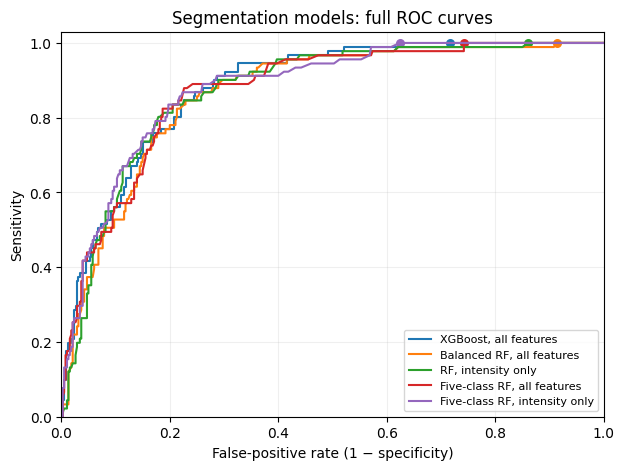

In [45]:
scored = {label: table for label, table in tables.items() if "proba_1" in table}
zero = pd.DataFrame({label: zero_fn_summary(y, score(table)) for label, table in scored.items()}).T
zero["training"] = ["binary" if label in binary_models else "five-class" for label in zero.index]
zero["macro F1"] = [
    f1_score(y, score(scored[label]).ge(zero.loc[label, "threshold"]),
             labels=[0, 1], average="macro", zero_division=0)
    for label in zero.index
]
display(zero[["training", "threshold"] + binary_report_columns].rename(columns={
    "balanced_accuracy": "balanced accuracy", "sensitivity": "recall",
}).round(3))

fig, ax = plt.subplots(figsize=(7, 5))
for label, table in scored.items():
    fpr, tpr, _ = roc_curve(y, score(table), drop_intermediate=False)
    ax.plot(fpr, tpr, label=label)
    ax.scatter(1 - zero.loc[label, "specificity"], 1, s=30)
ax.set(xlabel="False-positive rate (1 − specificity)", ylabel="Sensitivity",
       title="Segmentation models: full ROC curves", xlim=(0, 1), ylim=(0, 1.03))
ax.legend(fontsize=8, loc="lower right")
ax.grid(alpha=0.2)
plt.show()

### 11.3 Historical default-decision errors

The default decision and the high-sensitivity objective are different. Binary XGBoost misses 33 positives at its default decision. Of these, 31 have a reader mean from 3.5 to 4 and two have a mean above 4. Missed positives have a median mask-equivalent diameter of 5.8 mm, versus 10.7 mm for detected positives. Twenty-two of the 33 misses have only one reader. These associations do not prove why an individual error occurred.

The next table groups the positive nodules by their reader mean. The size columns compare detected and missed positives.

The final rows show the lowest-scoring positives for the intensity-based five-class reference. A very low score on even one positive forces the zero-FN threshold down and creates many false alerts.

,positive nodules,FN,"median diameter, missed (mm)","median diameter, detected (mm)"
reader mean,,,,
3.5 to 4,69,31,5.83,9.97
above 4,19,2,6.35,12.38
"above 3, below 3.5",3,0,NaN,10.59


,,ratings,target_regression_mean,diameter_mm,score
LNDbID,FindingID,,,,
69,2,[4.0],4.0,4.463,0.046
229,3,[4.0],4.0,3.499,0.052
270,5,[4.0],4.0,6.801,0.052
243,1,[4.0],4.0,4.779,0.052
53,2,"[5.0, 5.0]",5.0,4.040,0.060


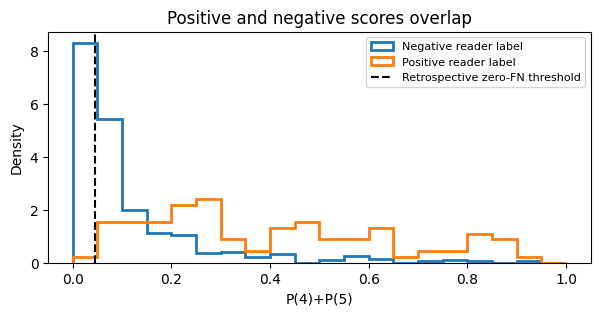

In [46]:
shape = pd.read_csv(
    ROOT / "data/lndb_ge3_segmentation_3d_c50_hu.csv",
    usecols=KEYS + ["original_shape_MeshVolume"],
).set_index(KEYS)
audit = readers.loc[shared, ["target_regression_mean", "ratings"]].join(shape)
audit["diameter_mm"] = 2 * (3 * audit.original_shape_MeshVolume / (4 * np.pi)) ** (1 / 3)
audit["prediction"] = tables["XGBoost, all features"].prediction
positive = audit.loc[y.eq(1)].copy()
positive["reader mean"] = np.select(
    [positive.target_regression_mean.lt(3.5), positive.target_regression_mean.le(4)],
    ["above 3, below 3.5", "3.5 to 4"], default="above 4",
)
rows = []
for band, group in positive.groupby("reader mean", sort=False):
    missed = group.prediction.eq(0)
    rows.append({"reader mean": band, "positive nodules": len(group), "FN": int(missed.sum()),
                 "median diameter, missed (mm)": group.loc[missed, "diameter_mm"].median(),
                 "median diameter, detected (mm)": group.loc[~missed, "diameter_mm"].median()})
display(pd.DataFrame(rows).set_index("reader mean").round(2))

intensity_score = score(tables["Five-class RF, intensity only"])
hard = audit.loc[y.eq(1)].assign(score=intensity_score)
display(hard.nsmallest(5, "score")[["ratings", "target_regression_mean", "diameter_mm", "score"]].round(3))

fig, ax = plt.subplots(figsize=(7, 3))
for value, label in [(0, "Negative reader label"), (1, "Positive reader label")]:
    ax.hist(intensity_score.loc[y.eq(value)], bins=np.linspace(0, 1, 21),
            density=True, histtype="step", linewidth=2, label=label)
ax.axvline(zero.loc["Five-class RF, intensity only", "threshold"], color="black",
           linestyle="--", label="Retrospective zero-FN threshold")
ax.set(xlabel="P(4)+P(5)", ylabel="Density", title="Positive and negative scores overlap")
ax.legend(fontsize=8)
plt.show()

### 11.4 Separate threshold calibration and test folds

This is a separate experiment, not another operating point on the table above. For each saved test fold, the next fold calibrates the threshold and the remaining three train the model, with LIDC in training only. The fitted model is unchanged between calibration and test. The threshold retains every calibration positive. No test labels enter model fitting or threshold selection.

Confirmed duplicate CT copies are excluded, leaving **459 nodules: 85 positive and 374 negative**. Every test nodule is predicted once. The table reports test errors, not calibration errors. Recipes were explored on this dataset already, so an external test set would still be needed to confirm a final selected model.

In [47]:
calibration_dir = ROOT / "models/segmentation_binary_calibration"
validation = pd.read_csv(calibration_dir / "validation_predictions.csv")
calibration_metrics = pd.read_csv(calibration_dir / "metrics.csv")
independent = calibration_metrics[calibration_metrics.fold.eq("overall_oof")].set_index("model")
assert independent.nodules.eq(459).all()
assert (independent.TP + independent.FN).eq(85).all()
display(independent[columns].round(3))

thresholds = validation.groupby(["model", "fold"], as_index=False).first()
print("Calibration positives per test fold:", sorted(thresholds.calibration_positives.unique()))
print("Zero calibration FN is a selection rule, not a guarantee of zero test FN.")

# Inspect positives that all three independently thresholded binary recipes miss.
keys = KEYS + ["fold"]
binary_validation = validation[validation.model.str.startswith("Binary ")]
alerts = binary_validation.pivot(index=keys, columns="model", values="prediction")
truth = binary_validation.drop_duplicates(keys).set_index(keys)[LABEL].reindex(alerts.index)
missed_by_all = alerts.index[truth.eq(1) & alerts.max(axis=1).eq(0)].droplevel("fold")
print("Positives missed by all three binary recipes:")
display(audit.loc[missed_by_all, ["ratings", "target_regression_mean", "diameter_mm"]].round(3))

,FN,FP,sensitivity,specificity,accuracy,precision
model,,,,,,
"Binary XGBoost, all features",4,161,0.953,0.570,0.641,0.335
"Binary Balanced RF, all features",3,212,0.965,0.433,0.532,0.279
"Binary RF, intensity",5,200,0.941,0.465,0.553,0.286
"Five-class RF, intensity, P(4)+P(5)",5,195,0.941,0.479,0.564,0.291


Calibration positives per test fold: [13, 16, 17, 19, 20]
Zero calibration FN is a selection rule, not a guarantee of zero test FN.
Positives missed by all three binary recipes:


,,ratings,target_regression_mean,diameter_mm
LNDbID,FindingID,,,
53,2,"[5.0, 5.0]",5.0,4.040
119,1,[4.0],4.0,5.183


### 11.5 Diameter filtering and tuning

The same 459 nodules, patient folds and separate threshold-calibration procedure are used in every row. Only binary XGBoost and binary Balanced RF are compared. The diameter filter removes features with absolute Spearman correlation above 0.9 or 0.7 with **maximum 3D diameter**, measured on fitting rows only. It does not use calibration or test rows.

For each model, tuning compares four settings including the unchanged baseline. The three outer-training LNDb folds rotate through inner fit, threshold calibration and validation, with LIDC in fitting only. Parameters are selected by the **fewest inner validation FN**, then the highest specificity. The outer calibration fold chooses the final threshold, and the untouched outer test fold measures performance.

The table reports test FN and FP, sensitivity, specificity, accuracy and the range of retained feature counts across outer folds. Only experiments with all five outer folds completed for both models are shown. These remain exploratory model comparisons on the same cohort, not an external confirmation.

In [48]:
experiments = {
    "Unchanged": "segmentation_binary_calibration",
    "Diameter correlation ≤0.9": "segmentation_binary_diameter09",
    "Diameter correlation ≤0.7": "segmentation_binary_diameter07",
    "Tuned": "segmentation_binary_tuned",
    "Tuned + diameter correlation ≤0.7": "segmentation_binary_diameter07_tuned",
}
model_names = ["Binary XGBoost, all features", "Binary Balanced RF, all features"]
rows = []
expected = validation[validation.model.isin(model_names)].set_index(
    ["model"] + KEYS
)[["fold", LABEL]].sort_index().astype(int)
for variant, directory in experiments.items():
    folder = ROOT / "models" / directory
    if not (folder / "metrics.csv").exists():
        continue
    run_metrics = pd.read_csv(folder / "metrics.csv")
    overall = run_metrics[run_metrics.fold.eq("overall_oof")]
    if not set(model_names).issubset(set(overall.model)):
        continue
    predictions = pd.read_csv(folder / "validation_predictions.csv")
    actual = predictions[predictions.model.isin(model_names)].set_index(
        ["model"] + KEYS
    )[["fold", LABEL]].sort_index().astype(int)
    assert actual.equals(expected), variant
    for name in model_names:
        result = run_metrics[run_metrics.model.eq(name) & run_metrics.fold.eq("overall_oof")].iloc[0]
        assert result.nodules == 459 and result.TP + result.FN == 85
        fold_rows = run_metrics[run_metrics.model.eq(name) & run_metrics.fold.ne("overall_oof")]
        counts = fold_rows.features if "features" in fold_rows else pd.Series([2060])
        rows.append({"model": name, "variant": variant,
                     "features": f"{int(counts.min())}–{int(counts.max())}",
                     **{column: result[column] for column in columns[:-1]}})
comparison = pd.DataFrame(rows).set_index(["model", "variant"])
display(comparison[["features"] + columns[:-1]].round(3))
best = comparison.sort_values(["FN", "specificity"], ascending=[True, False]).iloc[0]
print(f"Fewest test FN: {best.name[0]} — {best.name[1]}")
print(f"FN: {int(best.FN)}/85, accuracy: {best.accuracy:.1%}, specificity: {best.specificity:.1%}")

,,features,FN,FP,sensitivity,specificity,accuracy
model,variant,,,,,,
"Binary XGBoost, all features",Unchanged,2060–2060,4,161,0.953,0.570,0.641
"Binary Balanced RF, all features",Unchanged,2060–2060,3,212,0.965,0.433,0.532
"Binary XGBoost, all features",Diameter correlation ≤0.9,1961–1966,6,146,0.929,0.610,0.669
"Binary Balanced RF, all features",Diameter correlation ≤0.9,1961–1966,3,204,0.965,0.455,0.549
"Binary XGBoost, all features",Diameter correlation ≤0.7,1602–1615,4,180,0.953,0.519,0.599
"Binary Balanced RF, all features",Diameter correlation ≤0.7,1602–1615,2,212,0.976,0.433,0.534
"Binary XGBoost, all features",Tuned,2060–2060,4,179,0.953,0.521,0.601
"Binary Balanced RF, all features",Tuned,2060–2060,3,208,0.965,0.444,0.540
"Binary XGBoost, all features",Tuned + diameter correlation ≤0.7,1602–1615,5,169,0.941,0.548,0.621


Fewest test FN: Binary Balanced RF, all features — Tuned + diameter correlation ≤0.7
FN: 2/85, accuracy: 56.9%, specificity: 47.6%


### 11.6 Binary table for the main notebook

Inputs are `models/segmentation_binary_calibration/validation_predictions.csv` and `models/segmentation_binary_diameter07_tuned/validation_predictions.csv`. Baseline rows include the three binary-trained recipes. Filtered/tuned rows include XGBoost and Balanced RF.

Each row uses the same 459 findings, targets and patient folds, excluding the confirmed CT copies. Predictions retain their saved calibration thresholds. Metrics are recalculated from those predictions and checked against the saved overall metrics. AUC uses the saved test scores.

This exports `data/processed/radiomics_binary_results.csv` for the second table in main section 6.2. The `run` column identifies the directory and `recipe` identifies the model within its prediction CSV.

The copies were excluded from LNDb before assigning rows to training, calibration and test roles. The exclusion is enabled by `exclude_duplicate_lndb=True` in `src/binary_evaluation.py` and `src/binary_tuning.py`. The former records the excluded IDs in `models/segmentation_binary_calibration/excluded_ct_copies.csv`, and the latter records them in each run's `settings.json`. These experiments have 459 binary-labelled nodules (85 positive), compared with 471 (91 positive) in the historical default-decision comparison.

In [49]:
binary_report_runs = {
    "Baseline": "segmentation_binary_calibration",
    "Filtered + tuned": "segmentation_binary_diameter07_tuned",
}
recipe_labels = {
    "Binary XGBoost, all features": "XGBoost",
    "Binary Balanced RF, all features": "Balanced RF",
    "Binary RF, intensity": "RF, intensity only",
}
canonical_test = reference_folds.to_frame().join(readers[[LABEL]])
canonical_test = canonical_test.loc[
    ~canonical_test.index.get_level_values("LNDbID").isin(EXCLUDED_LNDB_IDS)
].sort_index()
assert len(canonical_test) == 459 and canonical_test[LABEL].sum() == 85
binary_report_rows, binary_report_tables = [], {}
for variant, directory in binary_report_runs.items():
    predictions = pd.read_csv(ROOT / "models" / directory / "validation_predictions.csv")
    saved_metrics = pd.read_csv(ROOT / "models" / directory / "metrics.csv")
    for recipe, label in recipe_labels.items():
        group = predictions.loc[predictions.model.eq(recipe)].set_index(KEYS).sort_index()
        if variant == "Filtered + tuned" and recipe == "Binary RF, intensity":
            continue
        assert group.index.is_unique
        pd.testing.assert_frame_equal(
            canonical_test, group[["fold", LABEL]], check_dtype=False,
        )
        assert group.prediction.eq(group.score.ge(group.threshold)).all()
        result = binary_report_scores(group[LABEL], group.prediction, group.score)
        stored = saved_metrics.loc[
            saved_metrics.model.eq(recipe) & saved_metrics.fold.eq("overall_oof")
        ]
        assert len(stored) == 1
        for column in ["nodules", "TP", "FN", "TN", "FP", "accuracy", "balanced_accuracy"]:
            np.testing.assert_allclose(result[column], stored.iloc[0][column], atol=1e-12, rtol=0)
        binary_report_rows.append({
            "model": label, "variant": variant, "run": directory, "recipe": recipe,
            "positives": int(group[LABEL].sum()), **result,
        })
        binary_report_tables[variant, label] = group

binary_report = pd.DataFrame(binary_report_rows).rename(columns={
    "balanced_accuracy": "balanced accuracy", "sensitivity": "recall",
})
report_path = ROOT / "data/processed/radiomics_binary_results.csv"
binary_report.to_csv(report_path, index=False)
display(binary_report.set_index(["model", "variant"])[[
    "FN", "FP", "accuracy", "balanced accuracy", "macro F1",
    "recall", "specificity", "precision", "AUC",
]].round(3))
print("Saved:", report_path.relative_to(ROOT))

,,FN,FP,accuracy,balanced accuracy,macro F1,recall,specificity,precision,AUC
model,variant,,,,,,,,,
XGBoost,Baseline,4,161,0.641,0.761,0.608,0.953,0.570,0.335,0.877
Balanced RF,Baseline,3,212,0.532,0.699,0.517,0.965,0.433,0.279,0.859
"RF, intensity only",Baseline,5,200,0.553,0.703,0.534,0.941,0.465,0.286,0.862
XGBoost,Filtered + tuned,5,169,0.621,0.745,0.591,0.941,0.548,0.321,0.871
Balanced RF,Filtered + tuned,2,196,0.569,0.726,0.549,0.976,0.476,0.297,0.865


Saved: data/processed/radiomics_binary_results.csv


### 11.7 Baseline versus filtered and tuned Balanced RF

The paired predictions below use the same 459 findings. The first table counts recovered positives, newly missed positives, removed false alerts and new false alerts. The second lists the remaining FN for the filtered/tuned model.

Ratings come from `data/processed/lndb_ge3_nodule_targets.csv`. Equivalent-sphere diameters are calculated from `original_shape_MeshVolume` in `data/lndb_ge3_segmentation_3d_c50_hu.csv`.

This exports `data/processed/radiomics_binary_errors.csv` for main section 7.1.

In [50]:
baseline_brf = binary_report_tables["Baseline", "Balanced RF"]
tuned_brf = binary_report_tables["Filtered + tuned", "Balanced RF"]
positive = baseline_brf[LABEL].eq(1)
negative = baseline_brf[LABEL].eq(0)
changes = pd.Series({
    "positives recovered": int((positive & baseline_brf.prediction.eq(0) & tuned_brf.prediction.eq(1)).sum()),
    "positives newly missed": int((positive & baseline_brf.prediction.eq(1) & tuned_brf.prediction.eq(0)).sum()),
    "false alerts removed": int((negative & baseline_brf.prediction.eq(1) & tuned_brf.prediction.eq(0)).sum()),
    "new false alerts": int((negative & baseline_brf.prediction.eq(0) & tuned_brf.prediction.eq(1)).sum()),
})
display(changes.to_frame("nodules"))

remaining = tuned_brf.loc[
    tuned_brf[LABEL].eq(1) & tuned_brf.prediction.eq(0),
    ["fold", "score", "threshold"],
].join(readers[["ratings", "target_regression_mean"]], validate="one_to_one")
remaining = remaining.join(shape[["original_shape_MeshVolume"]], validate="one_to_one")
assert remaining.notna().all().all()
remaining["diameter (mm)"] = 2 * (
    3 * remaining.original_shape_MeshVolume / (4 * np.pi)
) ** (1 / 3)
remaining = remaining.rename(columns={"target_regression_mean": "reader mean"})
remaining["run"] = binary_report_runs["Filtered + tuned"]
remaining["recipe"] = "Binary Balanced RF, all features"
remaining = remaining.drop(columns="original_shape_MeshVolume").reset_index()
report_path = ROOT / "data/processed/radiomics_binary_errors.csv"
remaining.to_csv(report_path, index=False)
display(remaining.set_index(KEYS)[[
    "ratings", "reader mean", "diameter (mm)", "score", "threshold",
]].round(3))
print("Saved:", report_path.relative_to(ROOT))

,nodules
positives recovered,1
positives newly missed,0
false alerts removed,22
new false alerts,6


,,ratings,reader mean,diameter (mm),score,threshold
LNDbID,FindingID,,,,,
53,2,"[5.0, 5.0]",5.0,4.040,0.082,0.123
119,1,[4.0],4.0,5.183,0.157,0.273


Saved: data/processed/radiomics_binary_errors.csv


Filtering and tuning recover one baseline Balanced RF miss, remove 22 false alerts and introduce six new false alerts. The remaining two FN include a nodule rated 5 by both readers. The high-sensitivity objective has not been reached on the separate evaluation folds.

### 11.8 Duplicate-excluded ROC for the main notebook

Inputs are the five saved test-score tables already checked in section 11.6: three baseline recipes from `models/segmentation_binary_calibration/validation_predictions.csv` and two filtered/tuned recipes from `models/segmentation_binary_diameter07_tuned/validation_predictions.csv`. All have the same 459 findings, including 85 positives, with confirmed CT copies excluded before fitting and fold evaluation.

Each curve uses the saved `score` and `target_binary_mean` columns. Its marked point uses the lowest positive score on those evaluated rows, with an alert for score ≥ threshold. These zero-FN points are retrospective. The separately calibrated decisions remain in the section 11.6 table.

Outputs for main section 6.2:
- `data/processed/radiomics_binary_roc.png`: the ROC figure.
- `data/processed/radiomics_binary_roc_points.csv`: zero-FN thresholds and metrics, with source `run` and `recipe` columns.

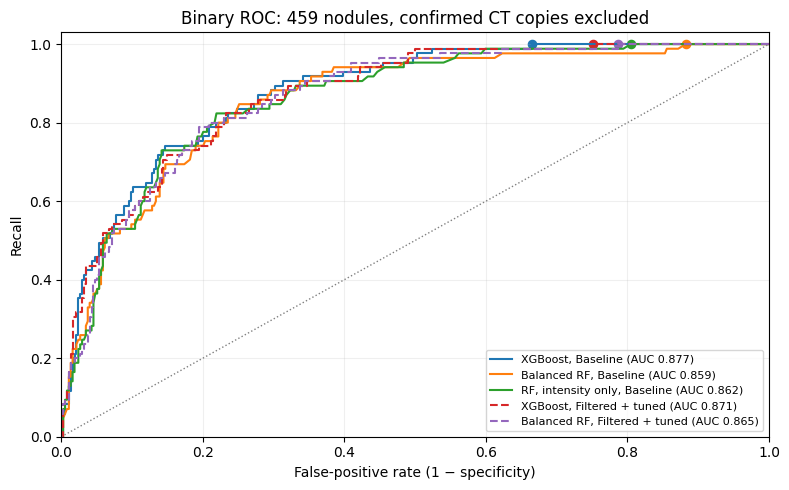

,,threshold,FN,FP,accuracy,specificity
model,variant,,,,,
XGBoost,Baseline,0.0168,0,249,0.4575,0.3342
Balanced RF,Baseline,0.0620,0,330,0.2810,0.1176
"RF, intensity only",Baseline,0.0440,0,301,0.3442,0.1952
XGBoost,Filtered + tuned,0.0255,0,281,0.3878,0.2487
Balanced RF,Filtered + tuned,0.0823,0,294,0.3595,0.2139


Zero-observed-FN ROC candidate: XGBoost, Baseline
Saved: data/processed/radiomics_binary_roc.png and data/processed/radiomics_binary_roc_points.csv


In [51]:
roc_point_rows = []
fig, ax = plt.subplots(figsize=(8, 5))
for (variant, model), group in binary_report_tables.items():
    pd.testing.assert_frame_equal(
        canonical_test, group[["fold", LABEL]], check_dtype=False,
    )
    point = zero_fn_summary(group[LABEL], group.score)
    point["macro F1"] = f1_score(
        group[LABEL], group.score.ge(point["threshold"]),
        labels=[0, 1], average="macro", zero_division=0,
    )
    recipe = next(name for name, label in recipe_labels.items() if label == model)
    roc_point_rows.append({
        "model": model, "variant": variant, "run": binary_report_runs[variant],
        "recipe": recipe, "positives": int(group[LABEL].sum()),
        "threshold selection": "evaluated rows", **point,
    })
    fpr, tpr, _ = roc_curve(group[LABEL], group.score, drop_intermediate=False)
    line, = ax.plot(
        fpr, tpr, linestyle="-" if variant == "Baseline" else "--",
        label=f"{model}, {variant} (AUC {point['AUC']:.3f})",
    )
    ax.scatter(1 - point["specificity"], 1, color=line.get_color(), s=35)

ax.plot([0, 1], [0, 1], linestyle=":", color="gray", linewidth=1)
ax.set(
    xlabel="False-positive rate (1 − specificity)", ylabel="Recall",
    title="Binary ROC: 459 nodules, confirmed CT copies excluded",
    xlim=(0, 1), ylim=(0, 1.03),
)
ax.legend(fontsize=8, loc="lower right")
ax.grid(alpha=0.2)
fig.tight_layout()
figure_path = ROOT / "data/processed/radiomics_binary_roc.png"
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

roc_points = pd.DataFrame(roc_point_rows).rename(columns={
    "balanced_accuracy": "balanced accuracy", "sensitivity": "recall",
})
report_path = ROOT / "data/processed/radiomics_binary_roc_points.csv"
roc_points.to_csv(report_path, index=False)
display(roc_points.set_index(["model", "variant"])[[
    "threshold", "FN", "FP", "accuracy", "specificity",
]].round(4))
zero_fn_choice = roc_points.sort_values("specificity", ascending=False).iloc[0]
assert zero_fn_choice.FN == 0
print(f"Zero-observed-FN ROC candidate: {zero_fn_choice.model}, {zero_fn_choice.variant}")
print("Saved:", figure_path.relative_to(ROOT), "and", report_path.relative_to(ROOT))